## Лабораторная №2. Классификация. Нейронные сети
### 1. Введение
**Цель работы:** изучение методов классификации данных, реализованные в библиотеке Scikit-Learn, а также ознакомление с нейронными сетями с использованием библиотек TensorFlow и TensorBoard. 
Постановка задачи:

1) Необходимо выбрать и подготовить датасет для классификации, затем построить классификационные модели с помощью пяти методов:

- Наивный Байесовский классификатор (GaussianNB, MultinomialNB, ComplementNB, BernoulliNB);

- Деревья решений (Decision Tree);

- Линейный дискриминантный анализ (Linear Discriminant Analysis);

- Метод опорных векторов (Support Vector Machines);

- Метод ближайших соседей (k-Nearest Neighbors);

2) Затем сравните качество работы классификаторов с помощью следующих метрик:

- Accuracy (точность),

- Precision (доля правильно классифицированных положительных примеров),

- Recall (чувствительность, доля верно найденных положительных примеров),

- F1-Score (среднее гармоническое precision и recall),

- Площадь под кривой ROC (AUC-ROC).

3) Настройте гиперпараметры каждого метода и проведите исследование влияния различных параметров на качество классификации.

4) Реализуйте и протестируйте нейронную сеть на TensorFlow, исследуйте эффект настройки гиперпараметров и визуализируйте процесс обучения с помощью инструмента TensorBoard.

### 2. Выбор и подготовка датасета
#### 2.1. Загрузка исходного набора данных

Для выполнения лабораторной работы выбран набор данных Telco Customer Churn, размещённый на платформе Kaggle. Набор содержит информацию о клиентах телекоммуникационной компании, включая характеристики используемых услуг, длительность обслуживания, способы оплаты и финансовые показатели.

Цель исследования - построение моделей бинарной классификации для прогнозирования оттока клиентов.

Целевой переменной является `Churn`, принимающая два значения:
- `Yes` - клиент прекратил пользоваться услугами компании;
- `No` - клиент продолжает пользоваться услугами компании.


In [7]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

RESULTS_PATH = Path("results")
RESULTS_PATH.mkdir(exist_ok=True)

df = pd.read_csv(
    "data/WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

print("Размерность датасета:", df.shape)
display(df.head())


Размерность датасета: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


**Анализ результатов**

В результате загрузки установлено, что набор данных Telco Customer Churn содержит 7043 наблюдения и 21 переменную.

Из них 19 переменных представляют собой входные признаки, одна переменная (`Churn`) является целевой, а `customerID` содержит уникальные идентификаторы клиентов и не будет использоваться при обучении моделей.

В наборе данных присутствуют числовые и категориальные признаки. К основным числовым характеристикам относятся `tenure` (продолжительность обслуживания), `MonthlyCharges` (ежемесячный платёж) и `TotalCharges` (общая сумма платежей).

В ходе предварительного анализа выявлено 11 пропущенных значений в признаке `TotalCharges` после преобразования его в числовой формат. Полностью дублирующихся записей не обнаружено.

Следовательно, перед обучением классификационных моделей необходимо обработать пропущенные значения, выполнить кодирование категориальных переменных и масштабирование соответствующих числовых признаков.

#### 2.2. Анализ распределения целевой переменной

Для решения задачи бинарной классификации необходимо исследовать распределение целевой переменной `Churn`, характеризующей факт прекращения обслуживания клиента.

Анализ соотношения классов позволяет определить степень сбалансированности набора данных и выбрать подходящие метрики оценки классификационных моделей.

Для визуализации распределения используется столбчатая диаграмма, отражающая количество клиентов каждого класса.

Количество клиентов:


,Количество
Churn,
No,5174
Yes,1869


Процентное соотношение:


,"Доля, %"
Churn,
No,73.46
Yes,26.54


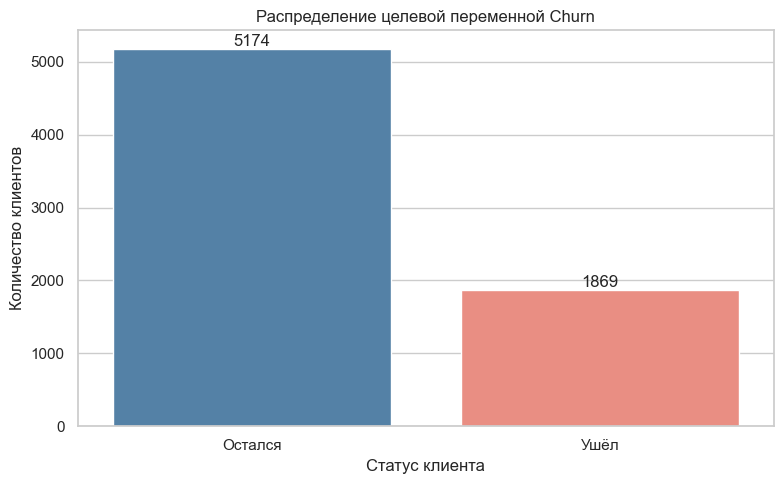

In [8]:

class_counts = df["Churn"].value_counts()

class_percent = (
    df["Churn"].value_counts(normalize=True) * 100
)

print("Количество клиентов:")
display(class_counts.to_frame("Количество"))

print("Процентное соотношение:")
display(class_percent.round(2).to_frame("Доля, %"))

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="Churn",
    order=["No", "Yes"],
    hue="Churn",
    palette={"No": "steelblue", "Yes": "salmon"},
    legend=False
)

plt.title("Распределение целевой переменной Churn")
plt.xlabel("Статус клиента")
plt.ylabel("Количество клиентов")
plt.xticks([0, 1], ["Остался", "Ушёл"])

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.savefig("results/churn_distribution.png", dpi=300)
plt.show()


**Анализ результатов**

По результатам анализа распределения целевой переменной установлено, что из 7043 клиентов 5174 (73,5%) продолжили пользоваться услугами компании, а 1869 (26,5%) прекратили обслуживание.

На построенной диаграмме наблюдается существенное преобладание клиентов класса `No` над клиентами класса `Yes`.

Таким образом, набор данных характеризуется умеренным дисбалансом классов. Количество клиентов, оставшихся в компании, приблизительно в 2,8 раза превышает количество ушедших.


#### 2.3. Анализ признаков и их взаимосвязей с оттоком клиентов

Для выявления характеристик, связанных с оттоком клиентов, проводится корреляционный анализ числовых переменных `tenure`, `MonthlyCharges` и `TotalCharges`.

Корреляционный анализ позволяет определить направление и силу линейной связи между числовыми признаками и целевой переменной.

Для вычисления коэффициентов корреляции целевая переменная `Churn` преобразуется в числовой формат: `No` соответствует 0, а `Yes` - 1.

Пропущенные значения:
tenure             0
MonthlyCharges     0
TotalCharges      11
Churn              0
dtype: int64


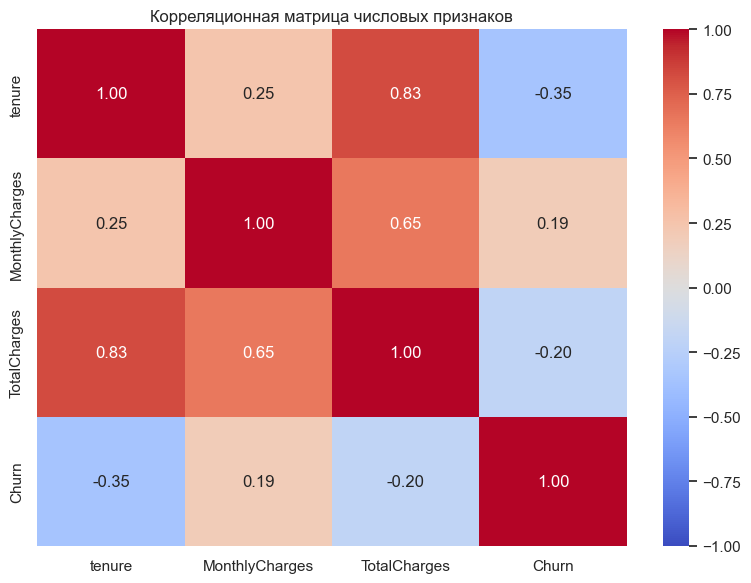


Корреляция с Churn:


,Коэффициент корреляции
tenure,-0.352
TotalCharges,-0.199
MonthlyCharges,0.193


In [9]:

numeric_df = df[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].copy()

for col in numeric_df.columns:
    numeric_df[col] = pd.to_numeric(
        numeric_df[col],
        errors="coerce"
    )

numeric_df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("Пропущенные значения:")
print(numeric_df.isnull().sum())

corr_matrix = numeric_df.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Корреляционная матрица числовых признаков")
plt.tight_layout()
plt.show()

print("\nКорреляция с Churn:")
display(
    corr_matrix["Churn"]
    .drop("Churn")
    .sort_values(key=abs, ascending=False)
    .round(3)
    .to_frame("Коэффициент корреляции")
)


**Анализ результатов корреляционного анализа**

В результате построения корреляционной матрицы выявлены взаимосвязи между числовыми признаками и целевой переменной `Churn`.

Наиболее выраженная отрицательная связь с оттоком наблюдается у признака `tenure` (коэффициент корреляции приблизительно -0,35). Это означает, что клиенты с большей продолжительностью обслуживания реже прекращают пользоваться услугами компании.

Признак `MonthlyCharges` имеет положительную корреляцию с оттоком (приблизительно 0,19). Следовательно, клиенты с более высокими ежемесячными платежами несколько чаще прекращают обслуживание.

Признак `TotalCharges` характеризуется слабой отрицательной корреляцией с оттоком (приблизительно -0,20). Это связано с тем, что общая сумма платежей во многом зависит от продолжительности обслуживания клиента.

Также выявлена сильная положительная корреляция между признаками `tenure` и `TotalCharges` (приблизительно 0,83). Такая взаимосвязь объясняется накоплением общей суммы платежей по мере увеличения продолжительности обслуживания.

Таким образом, среди исследованных числовых признаков наиболее выраженную линейную связь с оттоком имеет `tenure`. При этом высокая корреляция между `tenure` и `TotalCharges` свидетельствует о наличии мультиколлинеарности, которая может влиять на некоторые классификационные алгоритмы, в частности линейный дискриминантный анализ.

Указанные связи являются статистическими и сами по себе не доказывают причинно-следственных зависимостей.

Для дополнительного исследования факторов оттока рассматривается категориальный признак `Contract`, характеризующий продолжительность договора с клиентом.

Данный признак принимает три значения: `Month-to-month` (помесячный договор), `One year` (годовой договор), `Two year` (двухлетний договор).

Для каждой категории рассчитывается доля клиентов, прекративших обслуживание. Это позволяет определить, какие типы договоров связаны с повышенным уровнем оттока.

Доля оттока по типам договоров:


,"Доля оттока, %"
Contract,
Month-to-month,42.71
One year,11.27
Two year,2.83


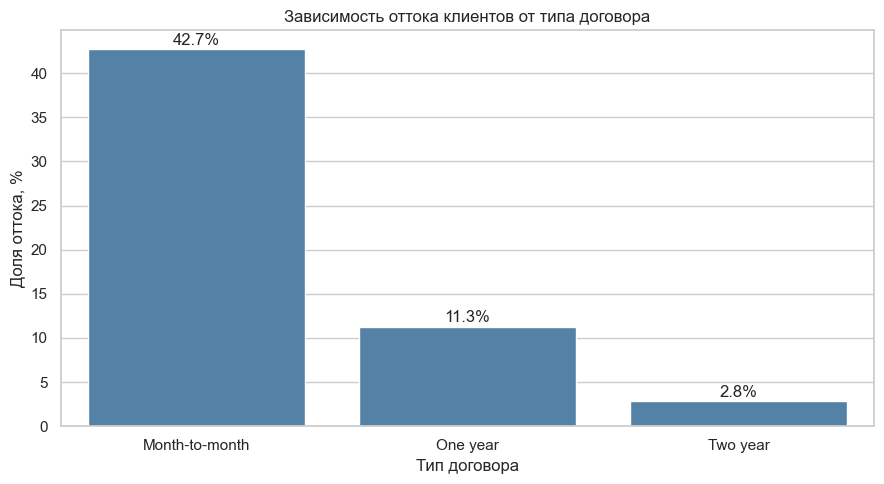

In [10]:

contract_churn = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

print("Доля оттока по типам договоров:")
display(
    contract_churn.round(2)
    .to_frame("Доля оттока, %")
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=contract_churn.index,
    y=contract_churn.values,
    color="steelblue"
)

plt.title("Зависимость оттока клиентов от типа договора")
plt.xlabel("Тип договора")
plt.ylabel("Доля оттока, %")

for i, value in enumerate(contract_churn.values):
    ax.text(
        i, value + 0.5,
        f"{value:.1f}%",
        ha="center"
    )

plt.tight_layout()
plt.savefig("results/contract_churn.png", dpi=300)
plt.show()


**Анализ результатов**

Анализ зависимости оттока от типа договора показал существенные различия между категориями клиентов.

Наибольшая доля оттока наблюдается среди клиентов с помесячным договором (`Month-to-month`) - приблизительно 42,7%.

Среди клиентов с годовыми договорами (`One year`) доля оттока составляет около 11,3%, а среди клиентов с двухлетними договорами (`Two year`) - около 2,8%.

Таким образом, клиенты с помесячными договорами прекращают обслуживание значительно чаще, чем клиенты с долгосрочными договорами.

Полученные результаты позволяют предположить, что тип договора является важным признаком для прогнозирования оттока. При этом выявленная статистическая зависимость не означает, что длительность договора сама по себе является причиной снижения оттока.


#### 2.4. Предварительная обработка данных

На данном этапе необходимо подготовить датасет Telco Customer Churn к обучению классификационных моделей. Для этого выполним обработку пропущенных значений, кодирование категориальных признаков и настройку масштабирования числовых переменных.

Для корректной предварительной обработки необходимо разделить признаки на числовые и категориальные.

Числовые признаки будут подвергаться заполнению пропусков и масштабированию, а категориальные - кодированию в числовой формат.

Из набора данных исключаются идентификатор клиента customerID и целевая переменная Churn, поскольку они не должны участвовать в преобразовании входных признаков.


In [11]:

X = df.drop(columns=["customerID", "Churn"])

numeric_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    col for col in X.columns
    if col not in numeric_features
]

print("Числовые признаки:")
print(numeric_features)

print("\nКатегориальные признаки:")
print(categorical_features)

print("\nКоличество признаков:", X.shape[1])


Числовые признаки:
['tenure', 'MonthlyCharges', 'TotalCharges']

Категориальные признаки:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Количество признаков: 19


В результате анализа выделены 3 числовых и 16 категориальных признаков, которые будут использоваться для построения классификационных моделей.

К числовым признакам относятся продолжительность обслуживания `tenure`, ежемесячный платёж `MonthlyCharges` и общая сумма платежей `TotalCharges`.

Остальные признаки, включая бинарный `SeniorCitizen`, рассматриваются как категориальные.

Всего для прогнозирования оттока используются 19 исходных признаков. Их разделение на группы позволяет применять соответствующие методы предварительной обработки.

Для обработки пропущенных числовых значений используется метод SimpleImputer, который заменяет пропуски медианой соответствующего признака.

Категориальные признаки преобразуются методом One-Hot Encoding, создающим отдельные бинарные столбцы для различных категорий.

Для масштабирования числовых признаков применяется StandardScaler, обеспечивающий стандартизацию данных. Дополнительно создаётся вариант с MinMaxScaler, необходимый для классификаторов, требующих неотрицательных значений признаков.

Все операции объединяются с помощью Pipeline и ColumnTransformer. Параметры преобразований будут вычисляться только по обучающей выборке после разделения данных.

In [12]:

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    OneHotEncoder
)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

nonnegative_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler())
])

preprocessor_nonnegative = ColumnTransformer([
    ("num", nonnegative_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Конвейеры предобработки успешно созданы.")


Конвейеры предобработки успешно созданы.



Для предварительной обработки данных созданы два конвейера преобразования признаков.

Первый конвейер предусматривает заполнение пропущенных числовых значений медианой, стандартизацию числовых переменных и кодирование категориальных признаков методом One-Hot Encoding.

Второй конвейер отличается использованием MinMaxScaler вместо StandardScaler. Он позволяет получать неотрицательные значения признаков, необходимые для применения MultinomialNB и ComplementNB.


Перед разделением исходного набора данных необходимо убедиться, что числовые переменные имеют корректные типы, целевая переменная содержит два класса, а матрица входных признаков сформирована правильно.

Также проверяется количество пропущенных значений, которые будут обработаны созданными конвейерами после разбиения выборки.

In [13]:

X["TotalCharges"] = pd.to_numeric(
    X["TotalCharges"],
    errors="coerce"
)

print("Размерность входных данных:", X.shape)

print("\nТипы числовых признаков:")
print(X[numeric_features].dtypes)

print("\nПропуски в признаках:")
print(X.isnull().sum()[lambda x: x > 0])

print("\nКлассы целевой переменной:")
print(df["Churn"].unique())


Размерность входных данных: (7043, 19)

Типы числовых признаков:
tenure              int64
MonthlyCharges    float64
TotalCharges      float64
dtype: object

Пропуски в признаках:
TotalCharges    11
dtype: int64

Классы целевой переменной:
['No' 'Yes']


Проверка показала, что матрица входных данных содержит 7043 наблюдения и 19 признаков.

Числовые переменные приведены к соответствующим типам данных. В признаке TotalCharges для стандартной версии датасета обнаруживаются 11 пропущенных значений, которые будут заполнены медианой при применении конвейера предобработки.

Целевая переменная Churn содержит два класса: Yes и No, что подтверждает постановку задачи бинарной классификации.

#### 2.5. Выводы по результатам первичного анализа данных

В ходе исследования набора данных Telco Customer Churn установлено, что он содержит 7043 наблюдения и 21 переменную, включая целевую переменную Churn. Для построения классификационных моделей выделены 19 входных признаков, а идентификатор клиента customerID исключён из дальнейшего анализа.

Анализ целевой переменной показал наличие дисбаланса классов: 73,5% клиентов продолжают пользоваться услугами компании, тогда как 26,5% прекратили обслуживание. Это обосновывает необходимость использования нескольких метрик для оценки качества классификации.

В результате корреляционного анализа установлено, что среди рассмотренных числовых признаков наиболее выраженную отрицательную связь с оттоком имеет продолжительность обслуживания tenure (r ≈ -0,35). Признак MonthlyCharges характеризуется слабой положительной корреляцией (r ≈ 0,19), а TotalCharges - слабой отрицательной (r ≈ -0,20). Между tenure и TotalCharges выявлена сильная положительная корреляция (r ≈ 0,83).

Анализ признака Contract показал, что наиболее высокая доля оттока наблюдается среди клиентов с помесячными договорами (около 42,7%), а наиболее низкая - среди клиентов с двухлетними договорами (около 2,8%).

В процессе подготовки данных выявлены 11 пропущенных значений в признаке TotalCharges, для обработки которых предусмотрено заполнение медианой. Определены 3 числовых и 16 категориальных признаков. Для преобразования категориальных данных выбран метод One-Hot Encoding, а для масштабирования числовых переменных - StandardScaler и MinMaxScaler.

С использованием инструментов Pipeline и ColumnTransformer созданы конвейеры предварительной обработки данных. Их применение будет осуществляться после разделения набора данных на обучающую и тестовую выборки, что позволит избежать утечки информации.



### 3. Разбиение выборки

На данном этапе разделим датасет Telco Customer Churn на обучающую и тестовую выборки, используя функцию train_test_split() библиотеки Scikit-Learn.

Для обеспечения воспроизводимости результатов зафиксируем случайное состояние random_state=42. После разбиения применим созданные в пункте 2.4 конвейеры предварительной обработки данных.

Для построения классификационных моделей необходимо выделить матрицу входных признаков X и целевую переменную y.

Матрица X содержит 19 признаков, характеризующих клиентов телекоммуникационной компании. Целевая переменная Churn преобразуется в числовой формат: No соответствует классу 0 (клиент остался), а Yes - классу 1 (клиент ушёл).

Идентификатор customerID исключается из набора входных признаков, поскольку он не несёт полезной информации для классификации.

In [14]:

X = df.drop(columns=["customerID", "Churn"])

y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("Размерность матрицы признаков:", X.shape)
print("Размерность целевой переменной:", y.shape)

print("\nРаспределение классов:")
display(y.value_counts().to_frame("Количество"))


Размерность матрицы признаков: (7043, 19)
Размерность целевой переменной: (7043,)

Распределение классов:


,Количество
Churn,
0,5174
1,1869


В результате сформирована матрица входных признаков X, содержащая 7043 наблюдения и 19 признаков, а также целевая переменная y, включающая 7043 значения.

Целевая переменная преобразована в бинарный числовой формат, необходимый для обучения классификационных моделей.

Количество объектов класса 0 составляет 5174, класса 1 - 1869. Полученные данные будут использованы для разделения на обучающую и тестовую выборки.

Для оценки обобщающей способности классификационных моделей данные разделяются на две части: 80% наблюдений используются для обучения, а оставшиеся 20% - для тестирования.

Разделение выполняется с помощью функции train_test_split() библиотеки Scikit-Learn.

Параметр random_state=42 обеспечивает воспроизводимость эксперимента, а stratify=y сохраняет приблизительно одинаковое соотношение классов в обучающей и тестовой выборках.

In [15]:

from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)

print("\nРаспределение обучающей выборки:")
print(y_train.value_counts())

print("\nРаспределение тестовой выборки:")
print(y_test.value_counts())


Обучающая выборка: (5634, 19)
Тестовая выборка: (1409, 19)

Распределение обучающей выборки:
Churn
0    4139
1    1495
Name: count, dtype: int64

Распределение тестовой выборки:
Churn
0    1035
1     374
Name: count, dtype: int64


Исходный набор данных разделён на обучающую и тестовую выборки в соотношении 80% и 20%.

Обучающая выборка содержит 5634 наблюдения, а тестовая - 1409 наблюдений. В обеих выборках сохранены 19 исходных входных признаков.

Использование стратифицированного разбиения позволило сохранить исходное соотношение классов.

Обучающая выборка будет использоваться для построения классификационных моделей и настройки их гиперпараметров. Тестовая выборка предназначена для итоговой оценки качества моделей на ранее неизвестных данных.

После разбиения данных необходимо убедиться, что соотношение классов Churn в обучающей и тестовой выборках соответствует исходному распределению.

Для этого рассчитываются процентные доли классов и строится сравнительная столбчатая диаграмма.

,Обучающая выборка,Тестовая выборка
Остался (0),73.46,73.46
Ушёл (1),26.54,26.54


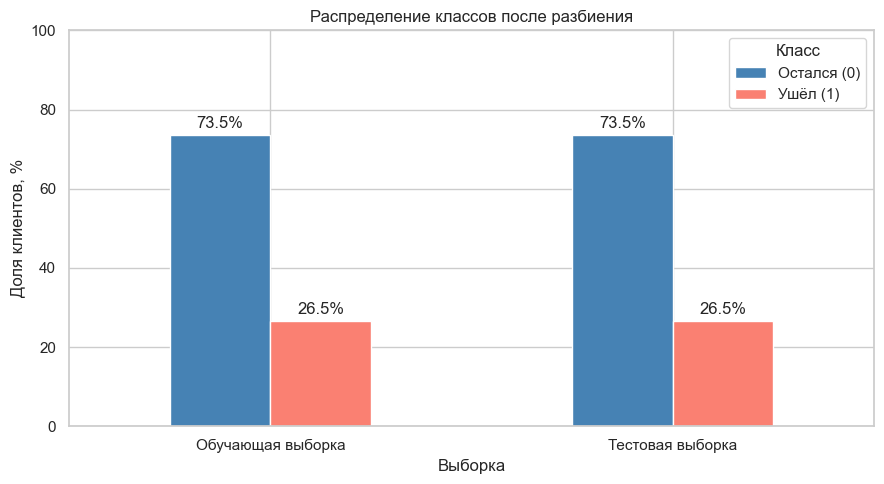

In [16]:

train_dist = y_train.value_counts(normalize=True) * 100
test_dist = y_test.value_counts(normalize=True) * 100

distribution = pd.DataFrame({
    "Обучающая выборка": train_dist,
    "Тестовая выборка": test_dist
}).sort_index()

distribution.index = ["Остался (0)", "Ушёл (1)"]

display(distribution.round(2))

ax = distribution.T.plot(
    kind="bar",
    figsize=(9, 5),
    color=["steelblue", "salmon"]
)

plt.title("Распределение классов после разбиения")
plt.xlabel("Выборка")
plt.ylabel("Доля клиентов, %")
plt.xticks(rotation=0)
plt.legend(title="Класс")
plt.ylim(0, 100)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.savefig("results/train_test_distribution.png", dpi=300)
plt.show()


Сравнение распределений целевой переменной показало, что в обучающей и тестовой выборках сохраняется практически одинаковое соотношение классов.

Доля клиентов, продолживших пользоваться услугами компании, составляет приблизительно 73,5%, а доля клиентов, прекративших обслуживание, - около 26,5% в каждой выборке.

После разбиения исходного набора данных выполняются заполнение пропущенных значений, кодирование категориальных признаков и масштабирование числовых переменных.

Параметры предварительной обработки определяются только на обучающей выборке с помощью метода fit_transform(). К тестовой выборке применяются уже полученные преобразования с помощью метода transform().


In [17]:

X_train["TotalCharges"] = pd.to_numeric(
    X_train["TotalCharges"],
    errors="coerce"
)

X_test["TotalCharges"] = pd.to_numeric(
    X_test["TotalCharges"],
    errors="coerce"
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

X_train_nonnegative = (
    preprocessor_nonnegative.fit_transform(X_train)
)

X_test_nonnegative = (
    preprocessor_nonnegative.transform(X_test)
)

print("Стандартная предобработка:")
print("Обучающая:", X_train_processed.shape)
print("Тестовая:", X_test_processed.shape)

print("\nПредобработка с MinMaxScaler:")
print("Обучающая:", X_train_nonnegative.shape)
print("Тестовая:", X_test_nonnegative.shape)

print("\nПропуски после обработки:")
print("Обучающая:", np.isnan(X_train_processed).sum())
print("Тестовая:", np.isnan(X_test_processed).sum())

print("\nМинимальное значение после MinMaxScaler:")
print(X_train_nonnegative.min())


Стандартная предобработка:
Обучающая: (5634, 46)
Тестовая: (1409, 46)

Предобработка с MinMaxScaler:
Обучающая: (5634, 46)
Тестовая: (1409, 46)

Пропуски после обработки:
Обучающая: 0
Тестовая: 0

Минимальное значение после MinMaxScaler:
0.0



После выполнения предварительной обработки получены числовые матрицы признаков для обучающей и тестовой выборок.

Пропущенные значения заполнены, категориальные признаки преобразованы методом One-Hot Encoding, а числовые переменные масштабированы.

Количество наблюдений осталось неизменным: 5634 объекта в обучающей выборке и 1409 объектов в тестовой. Количество столбцов увеличилось вследствие кодирования категориальных переменных.

Проверка подтвердила отсутствие пропущенных значений в преобразованных данных.

Для дальнейшего исследования подготовлены два варианта матриц признаков: со стандартизированными числовыми признаками и с неотрицательными признаками.

При настройке гиперпараметров в дальнейшем будут использоваться конвейеры, объединяющие предобработку и классификатор.

### 4. Методы классификации
#### 4.1. Наивный байесовский классификатор
Для обеспечения единообразного сравнения алгоритмов создаётся функция обучения и оценки качества классификации.

Функция выполняет обучение модели на тренировочной выборке, прогнозирование классов на тестовой выборке и вычисление метрик Accuracy, Precision, Recall, F1-score и ROC-AUC.

Полученные результаты сохраняются для дальнейшего сравнительного анализа методов классификации.


In [18]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

baseline_results = []
trained_models = {}
model_predictions = {}
model_probabilities = {}

def evaluate_model(name, model, X_train_data, X_test_data):
    model.fit(X_train_data, y_train)

    y_pred = model.predict(X_test_data)
    y_prob = model.predict_proba(X_test_data)[:, 1]

    metrics = {
        "Модель": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    }

    baseline_results.append(metrics)
    trained_models[name] = model
    model_predictions[name] = y_pred
    model_probabilities[name] = y_prob

    display(pd.DataFrame([metrics]).round(4))

    return model


Создана универсальная функция для обучения и оценки классификационных моделей.

Для каждой модели рассчитываются пять метрик качества на тестовой выборке. Результаты сохраняются в общей структуре данных для последующего сравнения.

Использование единого способа оценки обеспечивает сопоставимость результатов различных алгоритмов классификации.


Для исследования наивного байесовского подхода обучаются четыре модели: GaussianNB, MultinomialNB, ComplementNB и BernoulliNB.

GaussianNB обучается на стандартизированных данных. Для MultinomialNB и ComplementNB используются данные с неотрицательными признаками, полученные после применения MinMaxScaler.

Для BernoulliNB используется дополнительное бинарное преобразование признаков с порогом 0,5.

Все модели обучаются на одной обучающей выборке и оцениваются по одинаковым метрикам качества на тестовой выборке.

In [19]:

from sklearn.naive_bayes import (
    GaussianNB,
    MultinomialNB,
    ComplementNB,
    BernoulliNB
)

from sklearn.preprocessing import Binarizer

gaussian_nb = evaluate_model(
    "GaussianNB",
    GaussianNB(),
    X_train_processed,
    X_test_processed
)

multinomial_nb = evaluate_model(
    "MultinomialNB",
    MultinomialNB(),
    X_train_nonnegative,
    X_test_nonnegative
)

complement_nb = evaluate_model(
    "ComplementNB",
    ComplementNB(),
    X_train_nonnegative,
    X_test_nonnegative
)

binarizer = Binarizer(threshold=0.5)

X_train_binary = binarizer.transform(X_train_nonnegative)
X_test_binary = binarizer.transform(X_test_nonnegative)

bernoulli_nb = evaluate_model(
    "BernoulliNB",
    BernoulliNB(),
    X_train_binary,
    X_test_binary
)


,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,GaussianNB,0.6955,0.4597,0.8396,0.5941,0.8075


,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,MultinomialNB,0.709,0.4716,0.7995,0.5933,0.8066


,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,ComplementNB,0.6778,0.4438,0.8449,0.582,0.8066


,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,BernoulliNB,0.7182,0.4815,0.7995,0.601,0.8069


В результате эксперимента обучены четыре разновидности наивного байесовского классификатора: GaussianNB, MultinomialNB, ComplementNB и BernoulliNB.

Для каждого алгоритма выполнено прогнозирование оттока клиентов и рассчитаны метрики Accuracy, Precision, Recall, F1-score и ROC-AUC.

При обучении учитывались требования моделей к представлению входных данных. Для GaussianNB использованы стандартизированные признаки, для MultinomialNB и ComplementNB - неотрицательные значения, а для BernoulliNB - бинарные признаки.

Сравнение полученных метрик позволит определить наиболее эффективную разновидность наивного байесовского классификатора для рассматриваемого набора данных.

,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
3,BernoulliNB,0.7182,0.4815,0.7995,0.6010,0.8069
0,GaussianNB,0.6955,0.4597,0.8396,0.5941,0.8075
1,MultinomialNB,0.7090,0.4716,0.7995,0.5933,0.8066
2,ComplementNB,0.6778,0.4438,0.8449,0.5820,0.8066


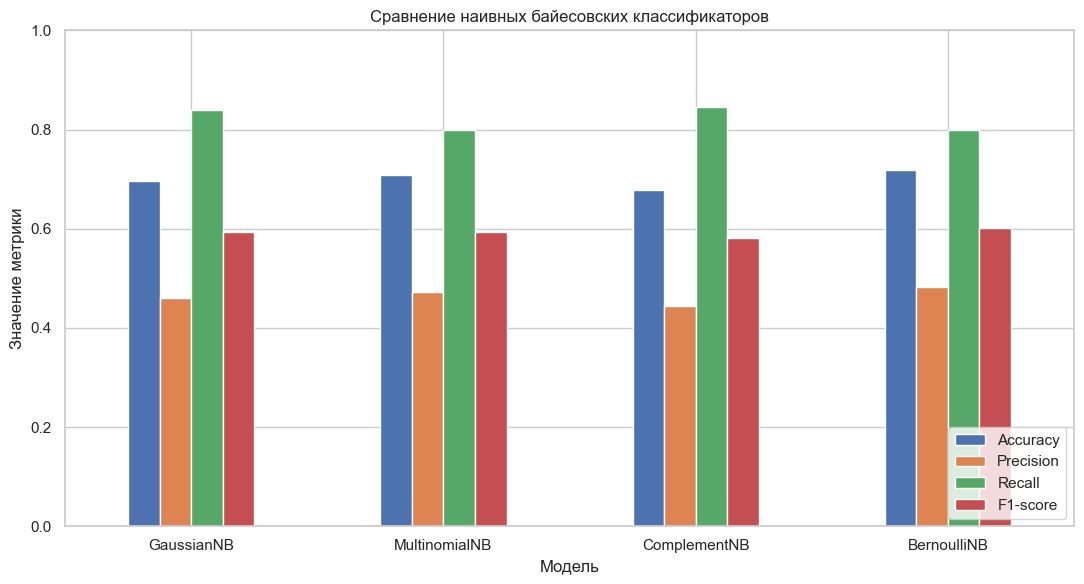

In [20]:

nb_results = pd.DataFrame(baseline_results)

display(
    nb_results.sort_values(
        by="F1-score",
        ascending=False
    ).round(4)
)

nb_results.set_index("Модель")[
    ["Accuracy", "Precision", "Recall", "F1-score"]
].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Сравнение наивных байесовских классификаторов")
plt.xlabel("Модель")
plt.ylabel("Значение метрики")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("results/naive_bayes_comparison.png", dpi=300)
plt.show()


В результате проведённого эксперимента выполнено сравнение четырёх разновидностей наивного байесовского классификатора: GaussianNB, MultinomialNB, ComplementNB и BernoulliNB.

Наибольшее значение Accuracy продемонстрировал BernoulliNB (около 0,72), что свидетельствует о наиболее высокой доле правильно классифицированных объектов среди рассматриваемых моделей. Также данный классификатор показал наилучшие значения Precision (около 0,48) и F1-score (около 0,60).

Наибольшее значение Recall наблюдается у ComplementNB и GaussianNB (около 0,84). Это означает, что данные модели способны выявлять примерно 84% клиентов, действительно прекративших пользоваться услугами компании. Однако сравнительно низкие значения Precision (около 0,44–0,46) указывают на значительное количество ложноположительных прогнозов.

Модель MultinomialNB продемонстрировала промежуточные результаты, а ComplementNB - наименьшие значения Accuracy и Precision среди рассмотренных алгоритмов.

Таким образом, BernoulliNB является наиболее эффективным классификатором по совокупности Accuracy, Precision и F1-score, тогда как GaussianNB и ComplementNB предпочтительнее в случаях, когда основной задачей является обнаружение максимального количества клиентов с риском оттока.

#### 4.2. Дерево решений

В качестве критерия разделения используется индекс Джини (gini), позволяющий оценивать неоднородность классов в узлах дерева. Для воспроизводимости результатов устанавливается random_state=42.

Обучение осуществляется на подготовленной обучающей выборке, после чего модель выполняет прогнозирование на тестовых данных.


In [21]:

from sklearn.tree import DecisionTreeClassifier

decision_tree = evaluate_model(
    "Decision Tree",
    DecisionTreeClassifier(
        criterion="gini",
        random_state=42
    ),
    X_train_processed,
    X_test_processed
)


,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Decision Tree,0.7253,0.4834,0.5053,0.4941,0.6549


Обучена модель дерева решений с критерием Джини. Программа рассчитывает пять метрик качества классификации и сохраняет результаты для дальнейшего сравнения.

Для дополнительной оценки качества классификации строится матрица ошибок (Confusion Matrix), отображающая количество правильных и неправильных прогнозов для каждого класса.

Особое внимание уделяется ложноотрицательным прогнозам, поскольку они соответствуют клиентам, которые фактически прекратили обслуживание, но были ошибочно отнесены моделью к оставшимся.

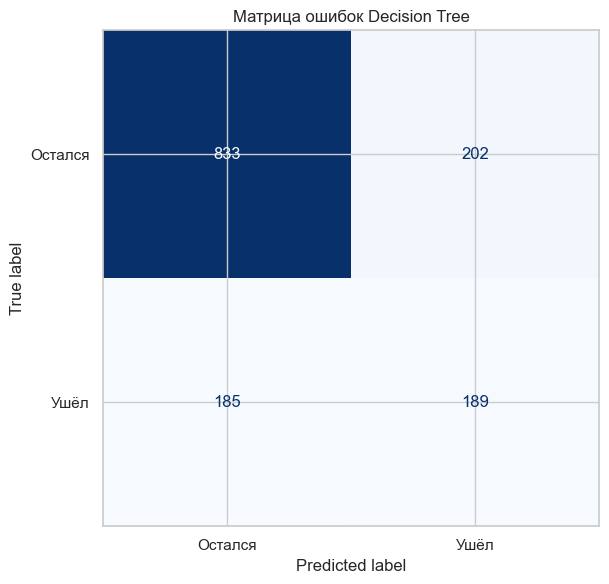

Матрица ошибок:
[[833 202]
 [185 189]]


In [22]:

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

y_pred_tree = decision_tree.predict(X_test_processed)

cm_tree = confusion_matrix(y_test, y_pred_tree)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_tree,
    display_labels=["Остался", "Ушёл"]
)

disp.plot(cmap="Blues", colorbar=False)

plt.title("Матрица ошибок Decision Tree")
plt.tight_layout()
plt.savefig("results/decision_tree_confusion.png", dpi=300)
plt.show()

print("Матрица ошибок:")
print(cm_tree)



Матрица ошибок содержит четыре значения:

|  | Предсказал «Остался» | Предсказал «Ушёл» |
|---|---|---|
| **Фактически остался** | TN — верно | FP — ошибка |
| **Фактически ушёл** | FN — ошибка | TP — верно |


Для определения наиболее информативных характеристик клиентов проводится анализ значимости признаков (feature_importances_).

Показатель значимости отражает вклад каждого признака в уменьшение неоднородности классов при построении дерева решений.

Результаты визуализируются с помощью столбчатой диаграммы десяти наиболее значимых признаков.

10 наиболее значимых признаков:


num__TotalCharges                      0.1925
num__MonthlyCharges                    0.1865
cat__Contract_Month-to-month           0.1661
num__tenure                            0.1184
cat__InternetService_Fiber optic       0.0528
cat__PaymentMethod_Electronic check    0.0213
cat__gender_Male                       0.0175
cat__TechSupport_No                    0.0153
cat__OnlineBackup_No                   0.0140
cat__PaperlessBilling_No               0.0139
dtype: float64

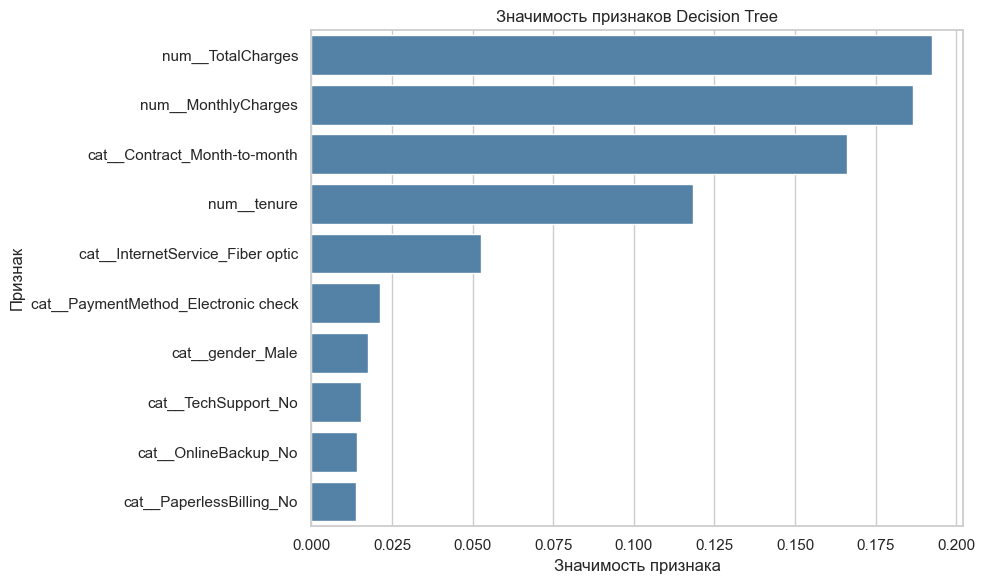

In [23]:

feature_names = preprocessor.get_feature_names_out()

importances = pd.Series(
    decision_tree.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

print("10 наиболее значимых признаков:")
display(importances.head(10).round(4))

plt.figure(figsize=(10, 6))

sns.barplot(
    x=importances.head(10).values,
    y=importances.head(10).index,
    color="steelblue"
)

plt.title("Значимость признаков Decision Tree")
plt.xlabel("Значимость признака")
plt.ylabel("Признак")

plt.tight_layout()
plt.savefig("results/decision_tree_features.png", dpi=300)
plt.show()


На графике отображаются десять признаков, наиболее активно использованных деревом решений при разделении клиентов на классы.

Чем выше значение feature_importances_, тем больший вклад признак внёс в уменьшение неоднородности узлов дерева.

In [24]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

y_prob_tree = decision_tree.predict_proba(
    X_test_processed
)[:, 1]

tree_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_tree),
    "Precision": precision_score(y_test, y_pred_tree),
    "Recall": recall_score(y_test, y_pred_tree),
    "F1-score": f1_score(y_test, y_pred_tree),
    "ROC-AUC": roc_auc_score(y_test, y_prob_tree)
}

print("Метрики Decision Tree:")

for metric, value in tree_metrics.items():
    print(f"{metric}: {value:.4f}")

tn, fp, fn, tp = cm_tree.ravel()

print("\nМатрица ошибок:")
print(f"TN: {tn}")
print(f"FP: {fp}")
print(f"FN: {fn}")
print(f"TP: {tp}")

print("\nНаиболее значимый признак:")
print(importances.index[0])
print(f"Значимость: {importances.iloc[0]:.4f}")


Метрики Decision Tree:
Accuracy: 0.7253
Precision: 0.4834
Recall: 0.5053
F1-score: 0.4941
ROC-AUC: 0.6549

Матрица ошибок:
TN: 833
FP: 202
FN: 185
TP: 189

Наиболее значимый признак:
num__TotalCharges
Значимость: 0.1925



На тестовой выборке получены следующие значения метрик: Accuracy - 0,7253, Precision - 0,4834, Recall - 0,5053, F1-score - 0,4941 и ROC-AUC - 0,6549.

Значение Accuracy показывает, что модель правильно классифицировала 72,53% клиентов. При этом Precision составляет 48,34%, то есть менее половины клиентов, отнесённых моделью к классу оттока, действительно прекратили обслуживание.

Значение Recall, равное 50,53%, свидетельствует о том, что модель обнаружила примерно половину клиентов, фактически ушедших из компании. F1-score составляет 0,4941, что указывает на сравнительно невысокое качество классификации положительного класса.

Анализ матрицы ошибок показал, что модель правильно определила 833 клиента, оставшихся в компании, и 189 клиентов, прекративших обслуживание. При этом 202 клиента были ошибочно отнесены к классу оттока, а 185 клиентов, фактически прекративших обслуживание, не были обнаружены.

Значение ROC-AUC составляет 0,6549, что свидетельствует об ограниченной способности модели различать два класса.

Наиболее значимым признаком при построении дерева решений оказался TotalCharges (общая сумма платежей) со значимостью 0,1925, что соответствует приблизительно 19,25% суммарной значимости признаков в модели.

Базовая модель Decision Tree продемонстрировала умеренную общую точность, но недостаточно высокое качество выявления клиентов, склонных к оттоку. 

#### 4.3. Линейный дискриминантный анализ
Для обучения используется LinearDiscriminantAnalysis с решателем lsqr и автоматической регуляризацией shrinkage="auto". Регуляризация помогает повысить устойчивость модели при наличии взаимосвязанных признаков.


In [25]:

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = evaluate_model(
    "LDA",
    LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    ),
    X_train_processed,
    X_test_processed
)


,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,LDA,0.7871,0.6101,0.5481,0.5775,0.8309


В результате обучения создана модель линейного дискриминантного анализа. Алгоритм использует характеристики клиентов для определения их принадлежности к одному из двух классов.

Для оценки качества прогнозирования строится матрица ошибок, отражающая количество правильных и неправильных классификаций.

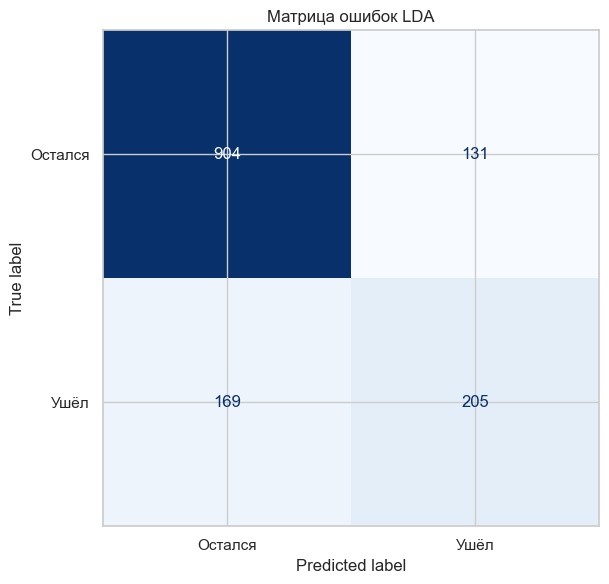

Матрица ошибок:
[[904 131]
 [169 205]]


In [26]:

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

y_pred_lda = lda.predict(X_test_processed)

cm_lda = confusion_matrix(y_test, y_pred_lda)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lda,
    display_labels=["Остался", "Ушёл"]
)

disp.plot(cmap="Blues", colorbar=False)

plt.title("Матрица ошибок LDA")
plt.tight_layout()
plt.savefig("results/lda_confusion.png", dpi=300)
plt.show()

print("Матрица ошибок:")
print(cm_lda)


Для исследования влияния признаков на прогнозирование оттока проводится анализ коэффициентов линейной дискриминантной функции.

Коэффициенты характеризуют направление и величину вклада признаков в формирование линейного правила классификации при фиксированных значениях остальных переменных.

Для визуализации выбираются десять признаков с наибольшими абсолютными значениями коэффициентов.

10 коэффициентов LDA с наибольшими модулями:


,Коэффициент
num__TotalCharges,-0.7801
cat__InternetService_Fiber optic,0.7458
cat__InternetService_DSL,-0.6861
cat__Contract_One year,-0.3956
cat__Contract_Month-to-month,0.3942
cat__PaymentMethod_Electronic check,0.3562
num__tenure,-0.2703
cat__StreamingMovies_Yes,0.2672
cat__StreamingTV_Yes,0.2672
cat__OnlineSecurity_No,0.2333


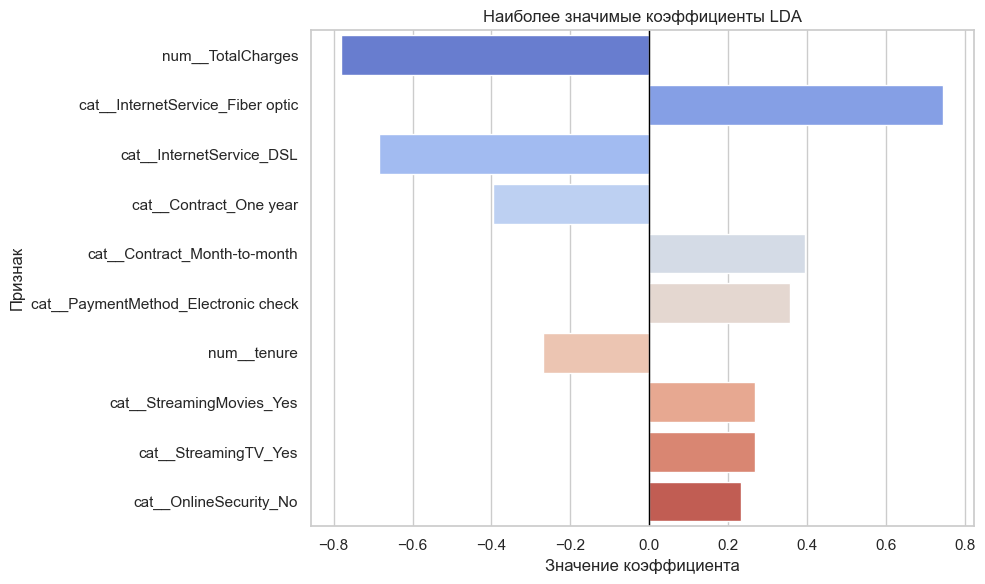

In [27]:

feature_names = preprocessor.get_feature_names_out()

lda_coef = pd.Series(
    lda.coef_[0],
    index=feature_names
)

top_lda_coef = (
    lda_coef.reindex(
        lda_coef.abs()
        .sort_values(ascending=False)
        .head(10)
        .index
    )
)

print("10 коэффициентов LDA с наибольшими модулями:")
display(top_lda_coef.round(4).to_frame("Коэффициент"))

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_lda_coef.values,
    y=top_lda_coef.index,
    hue=top_lda_coef.index,
    palette="coolwarm",
    legend=False
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Наиболее значимые коэффициенты LDA")
plt.xlabel("Значение коэффициента")
plt.ylabel("Признак")

plt.tight_layout()
plt.savefig("results/lda_coefficients.png", dpi=300)
plt.show()


В результате анализа коэффициентов линейного дискриминантного анализа определены десять признаков с наибольшими абсолютными значениями коэффициентов, влияющих на формирование разделяющей границы между классами.

Наибольший отрицательный коэффициент имеет признак TotalCharges (около -0,78), что указывает на снижение дискриминантной оценки оттока при увеличении общей суммы платежей. Также отрицательные коэффициенты наблюдаются у признаков InternetService_DSL (около -0,68), Contract_One year (около -0,39) и tenure (около -0,27).

Наибольший положительный коэффициент имеет признак InternetService_Fiber optic (около 0,74). Положительные коэффициенты также наблюдаются у признаков Contract_Month-to-month (около 0,40), PaymentMethod_Electronic check (около 0,36), StreamingMovies_Yes и StreamingTV_Yes (около 0,27), а также OnlineSecurity_No (около 0,23).

Положительные коэффициенты повышают дискриминантную оценку принадлежности клиента к классу оттока, тогда как отрицательные - снижают её при прочих равных условиях.

Таким образом, среди наиболее значимых для формирования линейной разделяющей границы признаков выделяются общая сумма платежей, тип интернет-подключения и условия договора. Полученные результаты свидетельствуют о том, что финансовые характеристики и особенности используемых услуг связаны с прогнозируемым оттоком клиентов.

Для итоговой оценки качества линейного дискриминантного анализа рассчитываются Accuracy, Precision, Recall, F1-score и ROC-AUC.

In [77]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

y_prob_lda = lda.predict_proba(
    X_test_processed
)[:, 1]

lda_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_lda),
    "Precision": precision_score(y_test, y_pred_lda),
    "Recall": recall_score(y_test, y_pred_lda),
    "F1-score": f1_score(y_test, y_pred_lda),
    "ROC-AUC": roc_auc_score(y_test, y_prob_lda)
}

print("Метрики LDA:")

for metric, value in lda_metrics.items():
    print(f"{metric}: {value:.4f}")

tn, fp, fn, tp = cm_lda.ravel()

print("\nМатрица ошибок:")
print(f"TN: {tn}")
print(f"FP: {fp}")
print(f"FN: {fn}")
print(f"TP: {tp}")

print("\nПризнак с наибольшим абсолютным коэффициентом:")
print(lda_coef.abs().idxmax())
print(f"Коэффициент: {lda_coef.loc[lda_coef.abs().idxmax()]:.4f}")


Метрики LDA:
Accuracy: 0.7871
Precision: 0.6101
Recall: 0.5481
F1-score: 0.5775
ROC-AUC: 0.8309

Матрица ошибок:
TN: 904
FP: 131
FN: 169
TP: 205

Признак с наибольшим абсолютным коэффициентом:
num__TotalCharges
Коэффициент: -0.7801


На тестовой выборке получены следующие значения метрик: Accuracy - 0,7871, Precision - 0,6101, Recall - 0,5481, F1-score - 0,5775 и ROC-AUC - 0,8309.

Значение Accuracy показывает, что модель правильно классифицировала 78,71% клиентов. Precision составляет 61,01%, то есть среди клиентов, отнесённых моделью к классу оттока, примерно 61% действительно прекратили обслуживание.

Значение Recall, равное 54,81%, свидетельствует о том, что модель обнаружила чуть больше половины клиентов, фактически ушедших из компании. F1-score составляет 0,5775, что указывает на умеренную эффективность классификации положительного класса.

Анализ матрицы ошибок показал, что модель правильно определила 904 клиента, оставшихся в компании, и 205 клиентов, прекративших обслуживание. При этом 131 клиент был ошибочно отнесён к классу оттока, а 169 клиентов, фактически прекративших обслуживание, не были обнаружены.

Значение ROC-AUC составляет 0,8309, что свидетельствует о достаточно высокой способности модели различать клиентов двух классов при изменении порога классификации.

Наибольший по абсолютной величине коэффициент дискриминантной функции имеет признак TotalCharges (общая сумма платежей), его значение составляет -0,7801. Отрицательный коэффициент указывает на снижение дискриминантной оценки оттока при увеличении данного признака при прочих равных условиях.

По сравнению с ранее исследованным классификатором Decision Tree модель LDA продемонстрировала более высокие значения всех пяти метрик. В частности, Accuracy увеличилась с 0,7253 до 0,7871, F1-score - с 0,4941 до 0,5775, а ROC-AUC - с 0,6549 до 0,8309.

Таким образом, LDA показал более высокое качество классификации, чем базовая модель дерева решений, и продемонстрировал хорошую способность различать клиентов, склонных к оттоку. Однако Recall остаётся сравнительно невысоким, поскольку модель не обнаруживает около 45% фактически ушедших клиентов.

#### 4.2. Метод опорных векторов

Алгоритм формирует разделяющую границу между двумя классами, стремясь обеспечить максимальное расстояние между границей и ближайшими обучающими объектами.

Для построения модели используется SVC с радиальным ядром rbf, параметром регуляризации C=1.0 и значением gamma="scale".

In [29]:

from sklearn.svm import SVC

svm = evaluate_model(
    "SVM",
    SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        probability=True,
        random_state=42
    ),
    X_train_processed,
    X_test_processed
)


,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,SVM,0.7906,0.6386,0.4866,0.5524,0.7932


В результате обучения построена модель классификации на основе метода опорных векторов с радиальным ядром RBF.

Для дополнительной оценки качества классификации строится матрица ошибок.

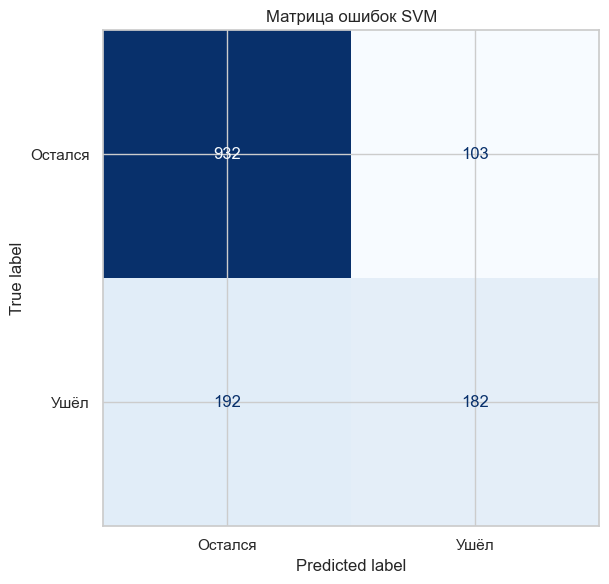

Матрица ошибок:
[[932 103]
 [192 182]]


In [30]:

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

y_pred_svm = svm.predict(X_test_processed)

cm_svm = confusion_matrix(y_test, y_pred_svm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=["Остался", "Ушёл"]
)

disp.plot(cmap="Blues", colorbar=False)

plt.title("Матрица ошибок SVM")
plt.tight_layout()
plt.savefig("results/svm_confusion.png", dpi=300)
plt.show()

print("Матрица ошибок:")
print(cm_svm)


Для оценки способности модели различать классы строится ROC-кривая.

График отображает зависимость доли правильно обнаруженных положительных объектов (True Positive Rate) от доли ошибочно классифицированных отрицательных объектов (False Positive Rate) при различных порогах классификации.

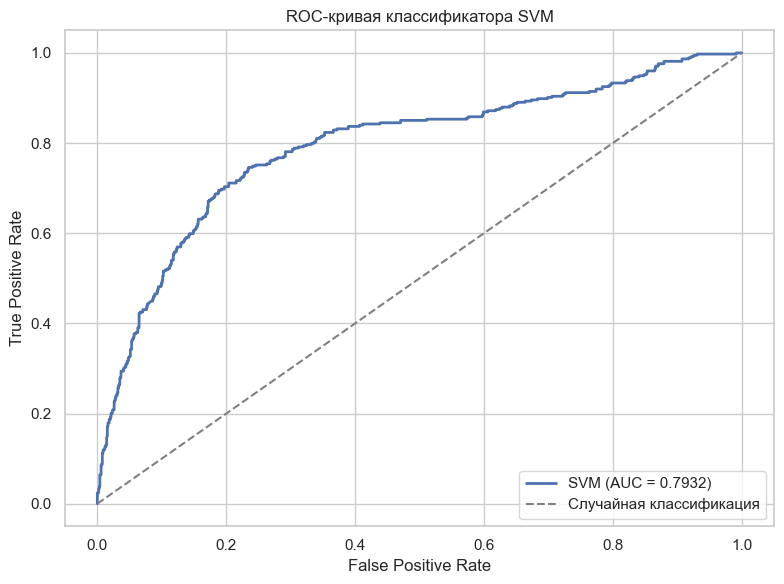

In [31]:

from sklearn.metrics import roc_curve, roc_auc_score

y_prob_svm = svm.predict_proba(
    X_test_processed
)[:, 1]

fpr_svm, tpr_svm, thresholds_svm = roc_curve(
    y_test,
    y_prob_svm
)

auc_svm = roc_auc_score(
    y_test,
    y_prob_svm
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_svm,
    tpr_svm,
    label=f"SVM (AUC = {auc_svm:.4f})",
    linewidth=2
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Случайная классификация"
)

plt.title("ROC-кривая классификатора SVM")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(True)

plt.tight_layout()
plt.savefig("results/svm_roc.png", dpi=300)
plt.show()


В результате построения ROC-кривой классификатора SVM получено значение ROC-AUC = 0,7932, что свидетельствует о достаточно хорошей способности модели различать клиентов, прекративших обслуживание, и клиентов, оставшихся в компании.

ROC-кривая располагается значительно выше диагональной линии, соответствующей случайной классификации (AUC = 0,5). Это подтверждает, что модель эффективно разделяет два класса на основе характеристик клиентов.

При доле ложноположительных срабатываний около 20% модель обнаруживает приблизительно 70% клиентов, фактически прекративших обслуживание. Это показывает, что изменение порога классификации позволяет увеличить полноту обнаружения оттока, однако сопровождается увеличением количества ложноположительных прогнозов.

По сравнению с ранее исследованной моделью LDA (ROC-AUC = 0,8309) классификатор SVM показал более низкое значение ROC-AUC на 0,0377. Следовательно, по данной метрике LDA лучше различает два класса.

Для итоговой оценки качества метода опорных векторов рассчитываются метрики Accuracy, Precision, Recall, F1-score и ROC-AUC.

Дополнительно определяются значения матрицы ошибок.

In [32]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

svm_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_svm),
    "Precision": precision_score(y_test, y_pred_svm),
    "Recall": recall_score(y_test, y_pred_svm),
    "F1-score": f1_score(y_test, y_pred_svm),
    "ROC-AUC": roc_auc_score(y_test, y_prob_svm)
}

print("Метрики SVM:")

for metric, value in svm_metrics.items():
    print(f"{metric}: {value:.4f}")

tn, fp, fn, tp = cm_svm.ravel()

print("\nМатрица ошибок:")
print(f"TN: {tn}")
print(f"FP: {fp}")
print(f"FN: {fn}")
print(f"TP: {tp}")

print("\nКоличество опорных векторов:")
print(svm.n_support_)

print("\nОбщее количество опорных векторов:")
print(svm.n_support_.sum())


Метрики SVM:
Accuracy: 0.7906
Precision: 0.6386
Recall: 0.4866
F1-score: 0.5524
ROC-AUC: 0.7932

Матрица ошибок:
TN: 932
FP: 103
FN: 192
TP: 182

Количество опорных векторов:
[1429 1220]

Общее количество опорных векторов:
2649



На тестовой выборке получены следующие значения метрик: Accuracy - 0,7906, Precision - 0,6386, Recall - 0,4866, F1-score - 0,5524 и ROC-AUC - 0,7932.

Значение Accuracy показывает, что модель правильно классифицировала 79,06% клиентов. Precision составляет 63,86%, то есть среди клиентов, отнесённых моделью к классу оттока, приблизительно 64% действительно прекратили обслуживание.

Значение Recall, равное 48,66%, свидетельствует о том, что модель обнаружила менее половины клиентов, фактически ушедших из компании. F1-score составляет 0,5524, что указывает на недостаточно высокий баланс между точностью и полнотой классификации положительного класса.

Анализ матрицы ошибок показал, что модель правильно определила 932 клиента, оставшихся в компании, и 182 клиента, прекративших обслуживание. При этом 103 клиента были ошибочно отнесены к классу оттока, а 192 клиента с фактическим оттоком не были обнаружены.

Значение ROC-AUC составило 0,7932, что свидетельствует о достаточно хорошей способности модели различать два класса при изменении порога классификации.

При построении разделяющей границы использовано 2649 опорных векторов, из которых 1429 относятся к классу 0, а 1220 - к классу 1.

По сравнению с ранее исследованным методом LDA классификатор SVM продемонстрировал более высокие значения Accuracy (0,7906 против 0,7871) и Precision (0,6386 против 0,6101). Однако LDA показал лучшие результаты по Recall (0,5481 против 0,4866), F1-score (0,5775 против 0,5524) и ROC-AUC (0,8309 против 0,7932).

#### 4.5. Метод ближайших соседей


Для реализации используется KNeighborsClassifier с количеством соседей n_neighbors=5, евклидовой метрикой расстояния и равными весами соседей.

In [33]:

from sklearn.neighbors import KNeighborsClassifier

knn = evaluate_model(
    "kNN",
    KNeighborsClassifier(
        n_neighbors=5,
        metric="euclidean",
        weights="uniform"
    ),
    X_train_processed,
    X_test_processed
)


,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,kNN,0.7573,0.5419,0.5535,0.5476,0.7882


Построим матрицу ошибок:

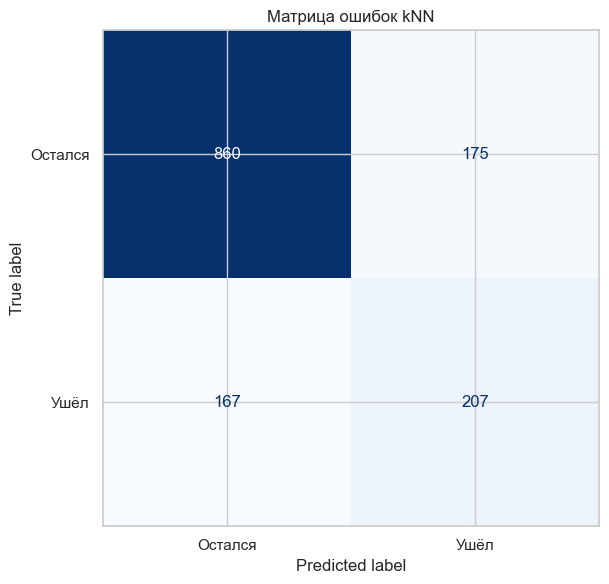

Матрица ошибок:
[[860 175]
 [167 207]]


In [34]:

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

y_pred_knn = knn.predict(X_test_processed)

cm_knn = confusion_matrix(y_test, y_pred_knn)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=["Остался", "Ушёл"]
)

disp.plot(cmap="Blues", colorbar=False)

plt.title("Матрица ошибок kNN")
plt.tight_layout()
plt.savefig("results/knn_confusion.png", dpi=300)
plt.show()

print("Матрица ошибок:")
print(cm_knn)


Для оценки способности классификатора различать клиентов, оставшихся в компании, и клиентов, прекративших обслуживание, строится ROC-кривая.

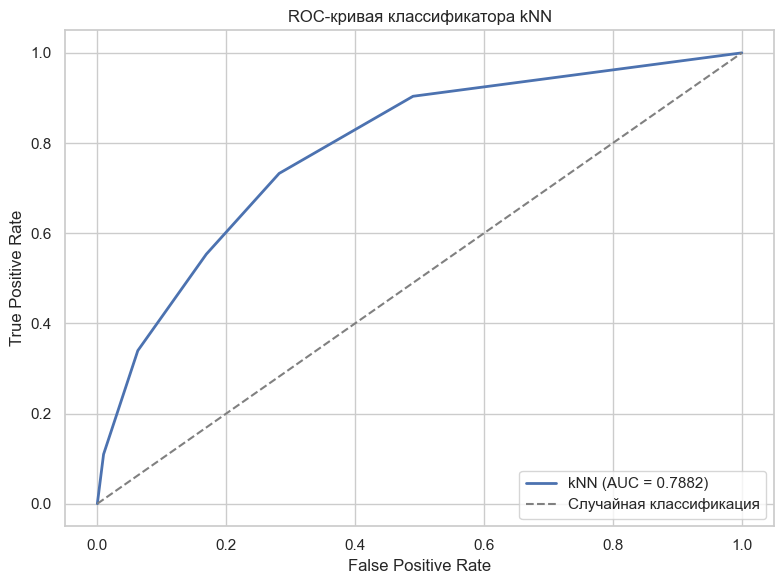

In [35]:

from sklearn.metrics import roc_curve, roc_auc_score

y_prob_knn = knn.predict_proba(
    X_test_processed
)[:, 1]

fpr_knn, tpr_knn, thresholds_knn = roc_curve(
    y_test,
    y_prob_knn
)

auc_knn = roc_auc_score(
    y_test,
    y_prob_knn
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_knn,
    tpr_knn,
    label=f"kNN (AUC = {auc_knn:.4f})",
    linewidth=2
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Случайная классификация"
)

plt.title("ROC-кривая классификатора kNN")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(True)

plt.tight_layout()
plt.savefig("results/knn_roc.png", dpi=300)
plt.show()


В результате построения ROC-кривой классификатора kNN получено значение ROC-AUC = 0,7882, что свидетельствует о достаточно хорошей способности модели различать клиентов, прекративших обслуживание, и клиентов, оставшихся в компании.

ROC-кривая располагается выше диагональной линии случайной классификации (AUC = 0,5), что подтверждает способность алгоритма разделять два класса лучше случайного ранжирования.

При доле ложноположительных срабатываний около 20% модель обнаруживает приблизительно 60% клиентов с фактическим оттоком. При увеличении доли ложноположительных срабатываний до 40% полнота обнаружения оттока возрастает примерно до 83%.

Кривая имеет ступенчатый характер, поскольку при использовании пяти ближайших соседей модель формирует ограниченное количество значений прогнозируемой вероятности.

По сравнению с ранее исследованными моделями LDA (ROC-AUC = 0,8309) и SVM (ROC-AUC = 0,7932) классификатор kNN показал более низкое значение ROC-AUC - на 0,0427 и 0,0050 соответственно.

Для итоговой оценки качества классификатора kNN рассчитываются Accuracy, Precision, Recall, F1-score и ROC-AUC.

In [36]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

knn_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_knn),
    "Precision": precision_score(y_test, y_pred_knn, zero_division=0),
    "Recall": recall_score(y_test, y_pred_knn, zero_division=0),
    "F1-score": f1_score(y_test, y_pred_knn, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob_knn)
}

print("Метрики kNN:")

for metric, value in knn_metrics.items():
    print(f"{metric}: {value:.4f}")

tn, fp, fn, tp = cm_knn.ravel()

print("\nМатрица ошибок:")
print(f"TN: {tn}")
print(f"FP: {fp}")
print(f"FN: {fn}")
print(f"TP: {tp}")

print("\nПараметры модели:")
print(f"Количество соседей: {knn.n_neighbors}")
print(f"Метрика расстояния: {knn.metric}")
print(f"Веса соседей: {knn.weights}")


Метрики kNN:
Accuracy: 0.7573
Precision: 0.5419
Recall: 0.5535
F1-score: 0.5476
ROC-AUC: 0.7882

Матрица ошибок:
TN: 860
FP: 175
FN: 167
TP: 207

Параметры модели:
Количество соседей: 5
Метрика расстояния: euclidean
Веса соседей: uniform


На тестовой выборке получены следующие значения метрик: Accuracy - 0,7573, Precision - 0,5419, Recall - 0,5535, F1-score - 0,5476 и ROC-AUC - 0,7882.

Значение Accuracy показывает, что модель правильно классифицировала 75,73% клиентов. Precision составляет 54,19%, то есть среди клиентов, отнесённых моделью к классу оттока, приблизительно 54% действительно прекратили обслуживание.

Значение Recall, равное 55,35%, свидетельствует о том, что модель обнаружила более половины клиентов, фактически прекративших обслуживание. F1-score составляет 0,5476, что указывает на умеренный баланс между точностью и полнотой классификации положительного класса.

Анализ матрицы ошибок показал, что модель правильно определила 860 клиентов, оставшихся в компании, и 207 клиентов, прекративших обслуживание. При этом 175 клиентов были ошибочно отнесены к классу оттока, а 167 клиентов с фактическим оттоком не были обнаружены.

Значение ROC-AUC составляет 0,7882, что свидетельствует о достаточно хорошей способности алгоритма различать два класса при изменении порога классификации.

По сравнению с ранее исследованными моделями kNN продемонстрировал наибольшее значение Recall (0,5535), немного превысив показатель LDA (0,5481). Это означает, что kNN обнаружил на два клиента с фактическим оттоком больше, чем LDA.

Однако по Accuracy, Precision, F1-score и ROC-AUC модель kNN уступила LDA. В частности, F1-score у kNN составил 0,5476 против 0,5775 у LDA, а ROC-AUC - 0,7882 против 0,8309.

### 5.Настройка гиперпараметров классификационных моделей

Гиперпараметры представляют собой настройки алгоритмов машинного обучения, задаваемые до начала обучения модели. Их выбор может существенно влиять на качество классификации.

Для поиска оптимальных параметров используется метод GridSearchCV, который последовательно проверяет различные комбинации гиперпараметров и оценивает их качество с помощью кросс-валидации.

В работе применяется стратифицированная трёхблочная кросс-валидация (StratifiedKFold) с фиксированным случайным состоянием random_state=42.

Основной метрикой оптимизации выбрана F1-score, поскольку набор данных содержит дисбаланс классов, а для задачи прогнозирования оттока важно учитывать одновременно Precision и Recall.


In [37]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import Binarizer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

searches = {}
tuned_results = []
parameter_results = {}

def tune_model(name, estimator, param_grid, preprocessing):
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessing)),
        ("model", estimator)
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="f1",
        cv=cv,
        n_jobs=2,
        refit=True
    )

    search.fit(X_train, y_train)

    y_pred = search.predict(X_test)

    if hasattr(search, "predict_proba"):
        y_score = search.predict_proba(X_test)[:, 1]
    else:
        y_score = search.decision_function(X_test)

    metrics = {
        "Модель": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_score)
    }

    searches[name] = search
    tuned_results.append(metrics)
    parameter_results[name] = pd.DataFrame(search.cv_results_)

    print(f"\nМодель: {name}")
    print("Лучшие параметры:", search.best_params_)
    print(f"Лучший F1 на кросс-валидации: {search.best_score_:.4f}")

    display(pd.DataFrame([metrics]).round(4))

    return search


Создана универсальная функция для автоматической настройки гиперпараметров классификационных моделей.

Для каждой комбинации параметров выполняется трёхблочная стратифицированная кросс-валидация. Качество оценивается по метрике F1-score, после чего выбирается комбинация с наибольшим средним значением данной метрики.

Предварительная обработка данных выполняется внутри конвейера обучения, поэтому параметры заполнения пропусков, кодирования и масштабирования определяются отдельно для каждого обучающего блока кросс-валидации.

После выбора оптимальных параметров модель повторно обучается на всей обучающей выборке и оценивается на тестовых данных.

#### 5.2. Настройка гиперпараметров наивных байесовских классификаторов

Для GaussianNB исследуется параметр var_smoothing, отвечающий за добавление небольшой величины к дисперсиям признаков с целью повышения численной устойчивости модели.

Для MultinomialNB и ComplementNB изменяется параметр alpha, управляющий сглаживанием вероятностных оценок.

Для каждого алгоритма выполняется поиск оптимальных значений параметров с использованием GridSearchCV и трёхблочной кросс-валидации.

В качестве критерия выбора лучшей комбинации используется F1-score.

In [38]:

from sklearn.naive_bayes import (
    GaussianNB,
    MultinomialNB,
    ComplementNB,
    BernoulliNB
)

gaussian_search = tune_model(
    "GaussianNB",
    GaussianNB(),
    {
        "model__var_smoothing": [1e-11, 1e-9, 1e-7, 1e-5]
    },
    preprocessor
)

multinomial_search = tune_model(
    "MultinomialNB",
    MultinomialNB(),
    {
        "model__alpha": [0.01, 0.1, 1.0, 5.0]
    },
    preprocessor_nonnegative
)

complement_search = tune_model(
    "ComplementNB",
    ComplementNB(),
    {
        "model__alpha": [0.01, 0.1, 1.0, 5.0]
    },
    preprocessor_nonnegative
)



Модель: GaussianNB
Лучшие параметры: {'model__var_smoothing': 1e-11}
Лучший F1 на кросс-валидации: 0.5969


,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,GaussianNB,0.6955,0.4597,0.8396,0.5941,0.8075



Модель: MultinomialNB
Лучшие параметры: {'model__alpha': 0.01}
Лучший F1 на кросс-валидации: 0.6093


,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,MultinomialNB,0.709,0.4716,0.7995,0.5933,0.8066



Модель: ComplementNB
Лучшие параметры: {'model__alpha': 0.01}
Лучший F1 на кросс-валидации: 0.5960


,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,ComplementNB,0.6785,0.4444,0.8449,0.5825,0.8066


Для модели GaussianNB оптимальным значением параметра var_smoothing стало 1e-11. Лучший F1-score при кросс-валидации составил 0,5969. На тестовой выборке получены Accuracy = 0,6955, Precision = 0,4597, Recall = 0,8396, F1-score = 0,5941 и ROC-AUC = 0,8075.

Для MultinomialNB оптимальным значением параметра alpha стало 0,01. F1-score при кросс-валидации составил 0,6093 - наибольшее значение среди трёх исследованных моделей. На тестовой выборке получены Accuracy = 0,7090, Precision = 0,4716, Recall = 0,7995, F1-score = 0,5933 и ROC-AUC = 0,8066.

Для ComplementNB оптимальным значением alpha также стало 0,01. Лучший F1-score при кросс-валидации составил 0,5960. На тестовой выборке получены Accuracy = 0,6785, Precision = 0,4444, Recall = 0,8449, F1-score = 0,5825 и ROC-AUC = 0,8066.

Сравнение результатов показало, что GaussianNB имеет наибольшие значения F1-score (0,5941) и ROC-AUC (0,8075) на тестовой выборке среди трёх рассматриваемых моделей. MultinomialNB демонстрирует наибольшие Accuracy (0,7090) и Precision (0,4716), тогда как ComplementNB обеспечивает максимальный Recall (0,8449).

Для классификатора BernoulliNB исследуется влияние параметра сглаживания alpha на качество прогнозирования.

Поскольку BernoulliNB использует бинарные признаки, перед обучением применяется преобразование Binarizer с порогом 0,5.

In [39]:

bernoulli_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor_nonnegative)),
    ("binarizer", Binarizer(threshold=0.5)),
    ("model", BernoulliNB())
])

bernoulli_search = GridSearchCV(
    bernoulli_pipeline,
    {
        "model__alpha": [0.01, 0.1, 1.0, 5.0]
    },
    scoring="f1",
    cv=cv,
    n_jobs=2
)

bernoulli_search.fit(X_train, y_train)

y_pred = bernoulli_search.predict(X_test)
y_prob = bernoulli_search.predict_proba(X_test)[:, 1]

bernoulli_metrics = {
    "Модель": "BernoulliNB",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}

searches["BernoulliNB"] = bernoulli_search
tuned_results.append(bernoulli_metrics)
parameter_results["BernoulliNB"] = pd.DataFrame(
    bernoulli_search.cv_results_
)

print("Лучшие параметры:", bernoulli_search.best_params_)
print(f"Лучший F1 на кросс-валидации: {bernoulli_search.best_score_:.4f}")

display(pd.DataFrame([bernoulli_metrics]).round(4))


Лучшие параметры: {'model__alpha': 1.0}
Лучший F1 на кросс-валидации: 0.6106


,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,BernoulliNB,0.7182,0.4815,0.7995,0.601,0.8069


Оптимальным значением параметра сглаживания стало alpha = 1,0. При этом лучший F1-score на кросс-валидации составил 0,6106.

На тестовой выборке получены следующие значения метрик: Accuracy - 0,7182, Precision - 0,4815, Recall - 0,7995, F1-score - 0,6010 и ROC-AUC - 0,8069.

Значение Accuracy показывает, что модель правильно классифицировала 71,82% клиентов. Precision составляет 48,15%, что свидетельствует о значительном количестве ложноположительных прогнозов.

График зависимости F1-score от значений исследуемых параметров:

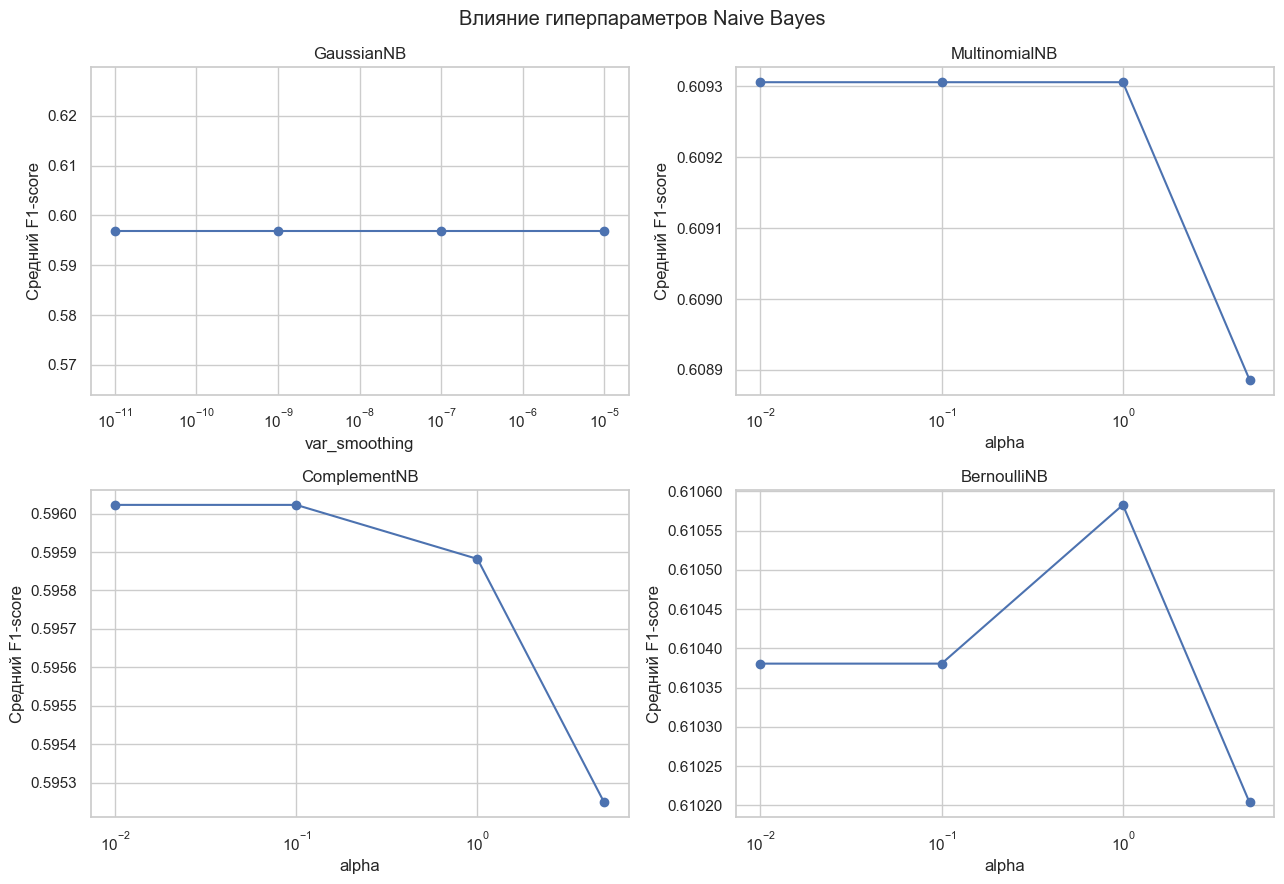

In [40]:

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

nb_parameters = {
    "GaussianNB": "model__var_smoothing",
    "MultinomialNB": "model__alpha",
    "ComplementNB": "model__alpha",
    "BernoulliNB": "model__alpha"
}

for ax, (name, parameter) in zip(axes.flat, nb_parameters.items()):
    data = parameter_results[name]

    x = data[f"param_{parameter}"].astype(float)
    y = data["mean_test_score"]

    ax.plot(x, y, marker="o")
    ax.set_xscale("log")
    ax.set_title(name)
    ax.set_xlabel(parameter.split("__")[-1])
    ax.set_ylabel("Средний F1-score")
    ax.grid(True)

plt.suptitle("Влияние гиперпараметров Naive Bayes")
plt.tight_layout()
plt.savefig("results/naive_bayes_tuning.png", dpi=300)
plt.show()


Настройка гиперпараметров показала, что GaussianNB практически не чувствителен к изменению var_smoothing: F1-score сохраняется на уровне 0,5969.

Для MultinomialNB и ComplementNB увеличение параметра alpha до 5 приводит к незначительному снижению F1-score. Наилучшие результаты достигаются при alpha = 0,01.

Для BernoulliNB максимальный F1-score составляет 0,6106 при alpha = 1,0, а дальнейшее увеличение параметра ухудшает качество классификации.

Таким образом, BernoulliNB продемонстрировал наибольший F1-score при кросс-валидации среди четырёх моделей. При этом влияние исследованных гиперпараметров на качество классификации оказалось сравнительно небольшим.

#### 5.3. Настройка гиперпараметров дерева решений
Для улучшения качества классификатора Decision Tree выполняется настройка гиперпараметров max_depth, min_samples_split и min_samples_leaf.

Параметр max_depth ограничивает максимальную глубину дерева, min_samples_split задаёт минимальное количество объектов для разделения внутреннего узла, а min_samples_leaf - минимальное количество объектов в конечном узле.

Оптимальные значения определяются с помощью GridSearchCV по метрике F1-score.

In [41]:

from sklearn.tree import DecisionTreeClassifier

tree_search = tune_model(
    "Decision Tree",
    DecisionTreeClassifier(random_state=42),
    {
        "model__max_depth": [3, 5, 7, 10, None],
        "model__min_samples_split": [2, 10],
        "model__min_samples_leaf": [1, 5, 10]
    },
    preprocessor
)



Модель: Decision Tree
Лучшие параметры: {'model__max_depth': 5, 'model__min_samples_leaf': 10, 'model__min_samples_split': 2}
Лучший F1 на кросс-валидации: 0.5965


,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Decision Tree,0.7984,0.6347,0.5668,0.5989,0.8282


В результате настройки дерева решений определены оптимальные гиперпараметры: max_depth = 5, min_samples_leaf = 10, min_samples_split = 2. Лучший F1-score при кросс-валидации составил 0,5965.

На тестовой выборке получены значения Accuracy = 0,7984, Precision = 0,6347, Recall = 0,5668, F1-score = 0,5989 и ROC-AUC = 0,8282.

По сравнению с базовой моделью F1-score увеличился с 0,4941 до 0,5989, а ROC-AUC - с 0,6549 до 0,8282.

Таким образом, настройка гиперпараметров существенно улучшила качество классификации. 

Влияние глубины дерева на качество классификации:


,Глубина,mean_test_score
0,3.0,0.4748
1,5.0,0.5965
2,7.0,0.5532
3,10.0,0.5422
4,Без ограничения,0.5320


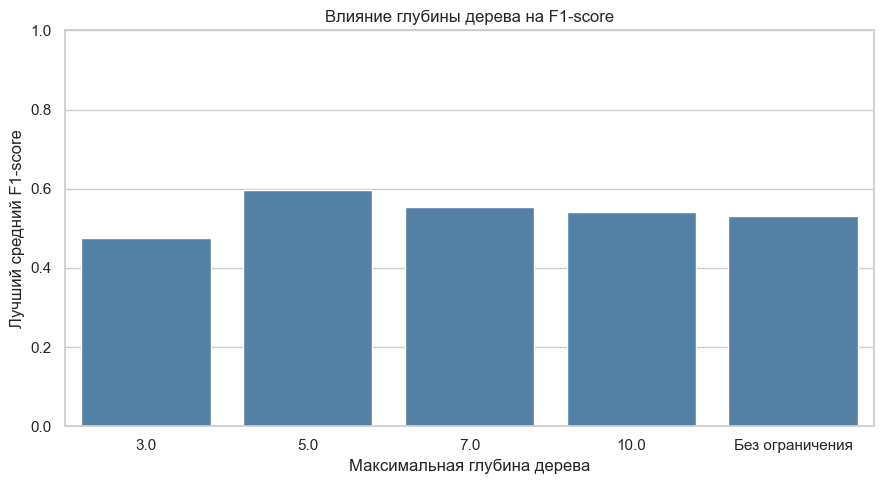

In [42]:

tree_cv = parameter_results["Decision Tree"].copy()

tree_depth_results = (
    tree_cv.groupby("param_model__max_depth", dropna=False)[
        "mean_test_score"
    ]
    .max()
    .reset_index()
)

tree_depth_results["Глубина"] = (
    tree_depth_results["param_model__max_depth"]
    .astype(str)
    .replace("nan", "Без ограничения")
)

display(tree_depth_results[["Глубина", "mean_test_score"]].round(4))

plt.figure(figsize=(9, 5))

sns.barplot(
    data=tree_depth_results,
    x="Глубина",
    y="mean_test_score",
    color="steelblue"
)

plt.title("Влияние глубины дерева на F1-score")
plt.xlabel("Максимальная глубина дерева")
plt.ylabel("Лучший средний F1-score")
plt.ylim(0, 1)

plt.tight_layout()
plt.savefig("results/decision_tree_tuning.png", dpi=300)
plt.show()


Наибольшее значение F1-score (0,5965) достигнуто при максимальной глубине дерева max_depth = 5.

При глубине 3 значение F1-score составляет 0,4748, что указывает на недостаточную сложность модели. При увеличении глубины до 7 и 10 качество снижается до 0,5532 и 0,5422 соответственно.

Дерево без ограничения глубины демонстрирует F1-score = 0,5320, что может свидетельствовать о переобучении модели.

Оптимальной среди исследованных является глубина 5, обеспечивающая наилучший баланс между сложностью дерева и качеством классификации на кросс-валидации.

#### 5.4. Настройка гиперпараметров линейного дискриминантного анализа

Для линейного дискриминантного анализа выполняется настройка коэффициента регуляризации shrinkage.

Данный параметр определяет степень регуляризации ковариационной матрицы, что позволяет повысить устойчивость модели при наличии коррелирующих признаков.

В ходе эксперимента исследуются значения shrinkage от 0 до 1, а также автоматический режим auto.

Для подбора параметров используется решатель lsqr и трёхблочная кросс-валидация по метрике F1-score.

In [43]:

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda_search = tune_model(
    "LDA",
    LinearDiscriminantAnalysis(solver="lsqr"),
    {
        "model__shrinkage": [
            0.0, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0, "auto"
        ]
    },
    preprocessor
)



Модель: LDA
Лучшие параметры: {'model__shrinkage': 0.7}
Лучший F1 на кросс-валидации: 0.6342


,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,LDA,0.7686,0.5498,0.7086,0.6192,0.8346


В результате настройки линейного дискриминантного анализа оптимальным значением параметра регуляризации стало shrinkage = 0,7. Лучший F1-score при кросс-валидации составил 0,6342.

На тестовой выборке получены значения Accuracy = 0,7686, Precision = 0,5498, Recall = 0,7086, F1-score = 0,6192 и ROC-AUC = 0,8346.

По сравнению с базовой моделью F1-score увеличился с 0,5775 до 0,6192, а Recall - с 0,5481 до 0,7086. При этом Accuracy снизилась с 0,7871 до 0,7686, а Precision - с 0,6101 до 0,5498.

Влияние регуляризации на качество LDA:

,shrinkage,mean_test_score
4,0.7,0.6342
3,0.5,0.6327
5,0.9,0.6269
2,0.3,0.6202
6,1.0,0.6175
0,0.0,0.6050
1,0.1,0.6027
7,auto,0.5969


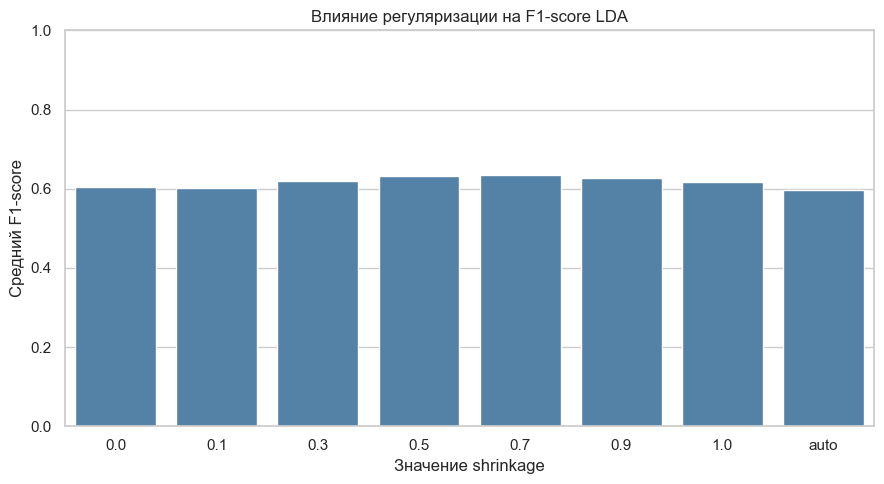

In [44]:

lda_cv = parameter_results["LDA"].copy()

lda_cv["shrinkage"] = (
    lda_cv["param_model__shrinkage"].astype(str)
)

display(
    lda_cv[["shrinkage", "mean_test_score"]]
    .sort_values("mean_test_score", ascending=False)
    .round(4)
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=lda_cv,
    x="shrinkage",
    y="mean_test_score",
    color="steelblue"
)

plt.title("Влияние регуляризации на F1-score LDA")
plt.xlabel("Значение shrinkage")
plt.ylabel("Средний F1-score")
plt.ylim(0, 1)

plt.tight_layout()
plt.savefig("results/lda_tuning.png", dpi=300)
plt.show()


Наибольшее значение F1-score (0,6342) достигнуто при shrinkage = 0,7. Близкий результат получен при shrinkage = 0,5 (0,6327).

При отсутствии регуляризации (shrinkage = 0) F1-score составляет 0,6050, а при автоматической регуляризации (auto) - 0,5969.

Увеличение параметра до 0,9 и 1,0 приводит к снижению F1-score до 0,6269 и 0,6175 соответственно.

Таким образом, умеренно высокая регуляризация улучшает качество LDA, а оптимальным среди исследованных значений является shrinkage = 0,7.

#### 5.5. Настройка гиперпараметров метода опорных векторов (SVM)

Для улучшения качества метода опорных векторов проводится исследование параметров регуляризации C, коэффициента gamma и типа ядра kernel.

Параметр C регулирует компромисс между шириной разделяющего зазора и ошибками классификации. Параметр gamma определяет характер влияния обучающих объектов на разделяющую границу при использовании RBF-ядра.

В ходе эксперимента сравниваются линейное и радиальное ядра, а также различные значения параметров регуляризации.

In [45]:

from sklearn.svm import SVC

svm_search = tune_model(
    "SVM",
    SVC(random_state=42),
    [
        {
            "model__kernel": ["linear"],
            "model__C": [0.1, 1, 10]
        },
        {
            "model__kernel": ["rbf"],
            "model__C": [0.1, 1, 10],
            "model__gamma": ["scale", 0.01, 0.1]
        }
    ],
    preprocessor
)



Модель: SVM
Лучшие параметры: {'model__C': 10, 'model__kernel': 'linear'}
Лучший F1 на кросс-валидации: 0.5863


,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,SVM,0.7864,0.613,0.5294,0.5681,0.8237


В результате настройки метода опорных векторов оптимальными параметрами стали C = 10 и kernel = "linear". Лучший F1-score при кросс-валидации составил 0,5863.

На тестовой выборке получены значения Accuracy = 0,7864, Precision = 0,6130, Recall = 0,5294, F1-score = 0,5681 и ROC-AUC = 0,8237.

По сравнению с базовой моделью SVM значение F1-score увеличилось с 0,5524 до 0,5681, Recall - с 0,4866 до 0,5294, а ROC-AUC - с 0,7932 до 0,8237. При этом Accuracy и Precision немного снизились.

Настройка гиперпараметров улучшила способность SVM выявлять клиентов с оттоком.

Влияние параметров SVM:

,kernel,C,mean_test_score
0,linear,0.1,0.5843
1,linear,1.0,0.5836
2,linear,10.0,0.5863
3,rbf,0.1,0.5388
4,rbf,1.0,0.5754
5,rbf,10.0,0.5678


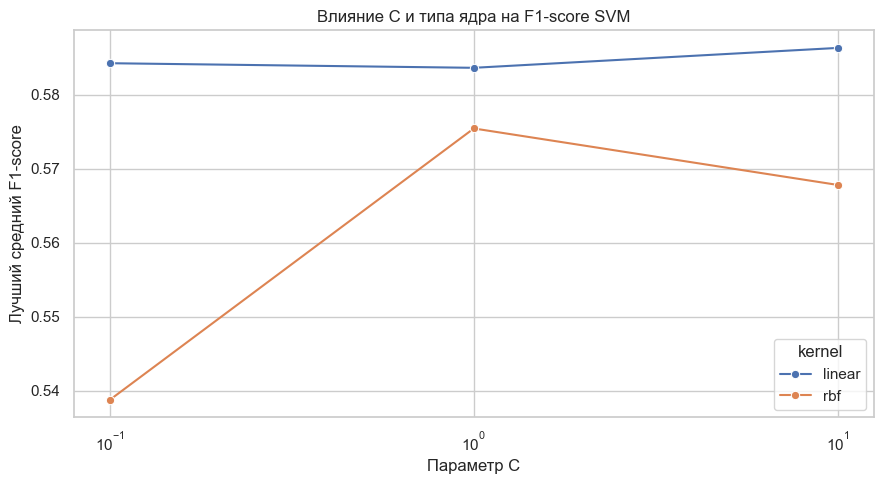

In [46]:

svm_cv = parameter_results["SVM"].copy()

svm_cv["kernel"] = svm_cv["param_model__kernel"].astype(str)
svm_cv["C"] = svm_cv["param_model__C"].astype(float)

svm_summary = (
    svm_cv.groupby(["kernel", "C"])["mean_test_score"]
    .max()
    .reset_index()
)

display(svm_summary.round(4))

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=svm_summary,
    x="C",
    y="mean_test_score",
    hue="kernel",
    marker="o"
)

plt.xscale("log")
plt.title("Влияние C и типа ядра на F1-score SVM")
plt.xlabel("Параметр C")
plt.ylabel("Лучший средний F1-score")
plt.grid(True)

plt.tight_layout()
plt.savefig("results/svm_tuning.png", dpi=300)
plt.show()


Наибольшее значение F1-score (0,5863) достигнуто при использовании линейного ядра (linear) и параметра регуляризации C = 10.

Для линейного ядра изменение параметра C практически не влияет на качество классификации: F1-score изменяется в пределах 0,5836–0,5863.

Для радиального ядра (rbf) наблюдается более выраженная зависимость от параметра C. При увеличении C с 0,1 до 1 F1-score возрастает с 0,5388 до 0,5754, однако при C = 10 снижается до 0,5678.

Линейное ядро продемонстрировало более высокие и стабильные результаты, чем RBF, при всех исследованных значениях C. Оптимальной среди рассмотренных комбинаций является kernel = "linear" и C = 10.

#### 5.6. Настройка гиперпараметров метода ближайших соседей (kNN)
Для улучшения качества классификатора kNN проводится исследование параметров n_neighbors, weights и metric.

Параметр n_neighbors определяет количество ближайших соседей, используемых для классификации нового объекта.

Параметр weights задаёт способ учёта голосов соседей: равные веса (uniform) или веса, обратно пропорциональные расстоянию (distance).

Параметр metric определяет способ вычисления расстояний между объектами. Исследуются евклидова и манхэттенская метрики.

In [47]:

from sklearn.neighbors import KNeighborsClassifier

knn_search = tune_model(
    "kNN",
    KNeighborsClassifier(),
    {
        "model__n_neighbors": [3, 5, 7, 11, 15, 21],
        "model__weights": ["uniform", "distance"],
        "model__metric": ["euclidean", "manhattan"]
    },
    preprocessor
)



Модель: kNN
Лучшие параметры: {'model__metric': 'manhattan', 'model__n_neighbors': 21, 'model__weights': 'uniform'}
Лучший F1 на кросс-валидации: 0.5986


,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,kNN,0.7771,0.5824,0.5668,0.5745,0.8249


В результате настройки метода ближайших соседей оптимальными параметрами стали n_neighbors = 21, metric = "manhattan" и weights = "uniform". Лучший F1-score при кросс-валидации составил 0,5986.

На тестовой выборке получены значения Accuracy = 0,7771, Precision = 0,5824, Recall = 0,5668, F1-score = 0,5745 и ROC-AUC = 0,8249.

По сравнению с базовой моделью F1-score увеличился с 0,5476 до 0,5745, а ROC-AUC - с 0,7882 до 0,8249. Accuracy также выросла с 0,7573 до 0,7771, а Recall - с 0,5535 до 0,5668.

Настройка гиперпараметров улучшила качество классификации kNN по всем пяти метрикам. 

Исследование влияния количества соседей:


,n_neighbors,mean_test_score
0,3,0.5124
1,5,0.5406
2,7,0.5576
3,11,0.5840
4,15,0.5891
5,21,0.5986


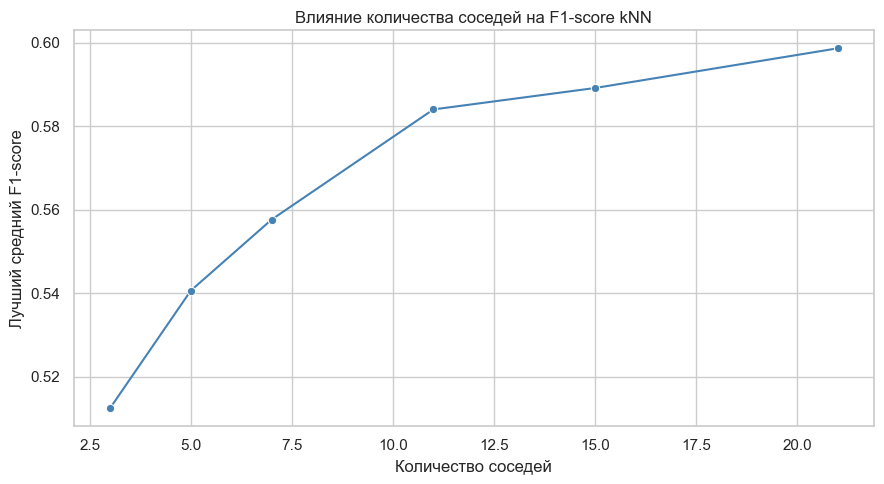

In [48]:

knn_cv = parameter_results["kNN"].copy()

knn_cv["n_neighbors"] = (
    knn_cv["param_model__n_neighbors"].astype(int)
)

knn_summary = (
    knn_cv.groupby("n_neighbors")["mean_test_score"]
    .max()
    .reset_index()
)

display(knn_summary.round(4))

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=knn_summary,
    x="n_neighbors",
    y="mean_test_score",
    marker="o",
    color="steelblue"
)

plt.title("Влияние количества соседей на F1-score kNN")
plt.xlabel("Количество соседей")
plt.ylabel("Лучший средний F1-score")
plt.grid(True)

plt.tight_layout()
plt.savefig("results/knn_tuning.png", dpi=300)
plt.show()


На графике наблюдается последовательное увеличение F1-score при увеличении количества ближайших соседей.

При n_neighbors = 3 значение F1-score составляет 0,5124, а при увеличении количества соседей до 11 возрастает до 0,5840.

Наибольшее значение F1-score = 0,5986 достигнуто при n_neighbors = 21, что на 0,0862 выше результата для трёх соседей.

Увеличение количества соседей положительно влияет на качество классификации в исследованном диапазоне. Оптимальным среди проверенных значений является n_neighbors = 21. 

#### 5.7. Сравнение результатов настройки гиперпараметров

После выполнения настройки гиперпараметров проводится сравнение базовых и оптимизированных классификационных моделей.

Для каждого алгоритма рассматриваются значения Accuracy, Precision, Recall, F1-score и ROC-AUC.

Особое внимание уделяется изменению F1-score, поскольку данная метрика использовалась в качестве критерия оптимизации при кросс-валидации.

Сравнение позволяет определить, какие классификаторы улучшили качество прогнозирования после настройки параметров, а для каких изменение гиперпараметров оказалось менее эффективным.

In [51]:

results_df = pd.DataFrame(baseline_results)

print("Результаты базовых моделей:")
display(results_df.round(4))

tuned_df = pd.DataFrame(tuned_results)

baseline_df = results_df.copy()

comparison = baseline_df.merge(
    tuned_df,
    on="Модель",
    suffixes=("_до", "_после")
)

comparison["Изменение F1"] = (
    comparison["F1-score_после"]
    - comparison["F1-score_до"]
)

comparison = comparison.sort_values(
    by="F1-score_после",
    ascending=False
)

display(comparison.round(4))

comparison.to_csv(
    "results/hyperparameter_comparison.csv",
    index=False
)


Результаты базовых моделей:


,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,GaussianNB,0.6955,0.4597,0.8396,0.5941,0.8075
1,MultinomialNB,0.7090,0.4716,0.7995,0.5933,0.8066
2,ComplementNB,0.6778,0.4438,0.8449,0.5820,0.8066
3,BernoulliNB,0.7182,0.4815,0.7995,0.6010,0.8069
4,Decision Tree,0.7253,0.4834,0.5053,0.4941,0.6549
5,LDA,0.7871,0.6101,0.5481,0.5775,0.8309
6,SVM,0.7906,0.6386,0.4866,0.5524,0.7932
7,kNN,0.7573,0.5419,0.5535,0.5476,0.7882


,Модель,Accuracy_до,Precision_до,Recall_до,F1-score_до,ROC-AUC_до,Accuracy_после,Precision_после,Recall_после,F1-score_после,ROC-AUC_после,Изменение F1
5,LDA,0.7871,0.6101,0.5481,0.5775,0.8309,0.7686,0.5498,0.7086,0.6192,0.8346,0.0417
3,BernoulliNB,0.7182,0.4815,0.7995,0.6010,0.8069,0.7182,0.4815,0.7995,0.6010,0.8069,0.0000
4,Decision Tree,0.7253,0.4834,0.5053,0.4941,0.6549,0.7984,0.6347,0.5668,0.5989,0.8282,0.1048
0,GaussianNB,0.6955,0.4597,0.8396,0.5941,0.8075,0.6955,0.4597,0.8396,0.5941,0.8075,0.0000
1,MultinomialNB,0.7090,0.4716,0.7995,0.5933,0.8066,0.7090,0.4716,0.7995,0.5933,0.8066,0.0000
2,ComplementNB,0.6778,0.4438,0.8449,0.5820,0.8066,0.6785,0.4444,0.8449,0.5825,0.8066,0.0005
7,kNN,0.7573,0.5419,0.5535,0.5476,0.7882,0.7771,0.5824,0.5668,0.5745,0.8249,0.0269
6,SVM,0.7906,0.6386,0.4866,0.5524,0.7932,0.7864,0.6130,0.5294,0.5681,0.8237,0.0158


По результатам настройки гиперпараметров установлено, что наибольшее улучшение F1-score продемонстрировало дерево решений (Decision Tree): показатель увеличился с 0,4941 до 0,5989 (+0,1048). ROC-AUC также значительно вырос - с 0,6549 до 0,8282.

Для LDA F1-score увеличился с 0,5775 до 0,6192 (+0,0417), а Recall - с 0,5481 до 0,7086. Модель показала наибольший F1-score и ROC-AUC (0,8346) среди всех настроенных классификаторов.

Для kNN F1-score вырос на 0,0269, для SVM - на 0,0158. Байесовские классификаторы продемонстрировали минимальные изменения качества, а BernoulliNB сохранил F1-score на уровне 0,6010.

Настройка гиперпараметров позволила улучшить качество большинства классификаторов. Наиболее существенный прирост показало дерево решений, однако лучшей моделью по F1-score и ROC-AUC после оптимизации стал LDA с параметром shrinkage = 0,7.

Визуализация изменения F1-score:

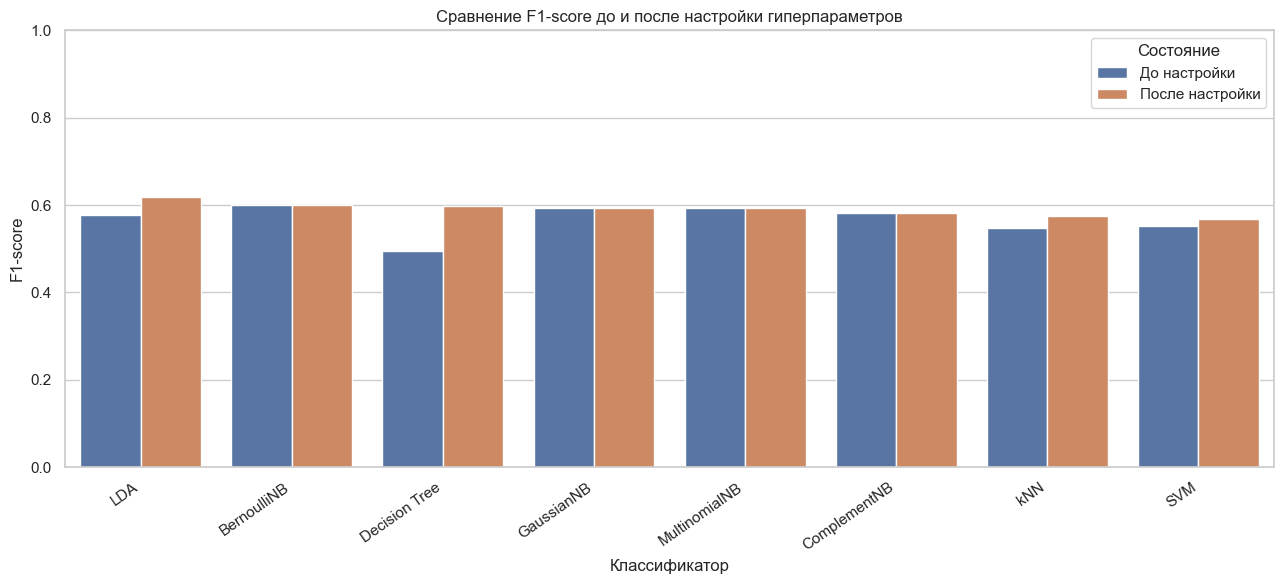

In [52]:

plot_data = comparison.melt(
    id_vars="Модель",
    value_vars=["F1-score_до", "F1-score_после"],
    var_name="Состояние",
    value_name="F1-score"
)

plot_data["Состояние"] = plot_data["Состояние"].replace({
    "F1-score_до": "До настройки",
    "F1-score_после": "После настройки"
})

plt.figure(figsize=(13, 6))

sns.barplot(
    data=plot_data,
    x="Модель",
    y="F1-score",
    hue="Состояние"
)

plt.title("Сравнение F1-score до и после настройки гиперпараметров")
plt.xlabel("Классификатор")
plt.ylabel("F1-score")
plt.xticks(rotation=35, ha="right")
plt.ylim(0, 1)

plt.tight_layout()
plt.savefig("results/hyperparameter_f1_comparison.png", dpi=300)
plt.show()


#### 5.8. Выводы по результатам настройки гиперпараметров
Для наивных байесовских классификаторов исследовано влияние параметров var_smoothing и alpha. Наилучший результат среди данных моделей продемонстрировал BernoulliNB с параметром alpha = 1,0, достигший F1-score = 0,6010. При этом ComplementNB обеспечил наибольшую полноту обнаружения оттока (Recall = 0,8449).

Наиболее существенное улучшение качества после настройки гиперпараметров продемонстрировало дерево решений (Decision Tree). При оптимальных значениях max_depth = 5, min_samples_leaf = 10 и min_samples_split = 2 показатель F1-score увеличился с 0,4941 до 0,5989, а ROC-AUC - с 0,6549 до 0,8282. Это свидетельствует о положительном влиянии ограничения сложности дерева на качество классификации.

Для линейного дискриминантного анализа (LDA) оптимальным значением регуляризации стало shrinkage = 0,7. После настройки F1-score увеличился с 0,5775 до 0,6192, Recall - с 0,5481 до 0,7086, а ROC-AUC достиг 0,8346.

Для метода опорных векторов (SVM) лучшими параметрами стали C = 10 и линейное ядро (linear). Значение F1-score увеличилось с 0,5524 до 0,5681. Для метода ближайших соседей (kNN) оптимальными оказались n_neighbors = 21, манхэттенская метрика расстояния и равные веса соседей. После настройки F1-score вырос с 0,5476 до 0,5745.

Сравнительный анализ показал, что настройка гиперпараметров улучшила F1-score большинства классификаторов, однако степень улучшения существенно различалась. Наибольший прирост F1-score наблюдался у дерева решений (+0,1048), тогда как байесовские классификаторы оказались менее чувствительными к изменению исследованных параметров.

Наиболее эффективной моделью по совокупности F1-score и ROC-AUC после настройки стал LDA, продемонстрировавший значения 0,6192 и 0,8346 соответственно. Кроме того, его Recall = 0,7086 показывает, что модель обнаруживает около 71% клиентов, фактически прекративших обслуживание.

### 6. Нейронная сеть на TensorFlow
Для реализации нейронной сети используются библиотеки TensorFlow и Keras.

Поскольку задача заключается в бинарной классификации, выходной слой нейронной сети будет содержать один нейрон с сигмоидной функцией активации, возвращающей значение от 0 до 1.

Для обучения используется матрица признаков, полученная после заполнения пропущенных значений, кодирования категориальных переменных и стандартизации числовых признаков.

Обучающая выборка дополнительно разделяется на обучающую и валидационную части в соотношении 80% и 20%. Валидационные данные используются для настройки архитектуры и гиперпараметров нейронной сети.


In [55]:

import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.base import clone
from sklearn.model_selection import train_test_split

tf.keras.utils.set_random_seed(42)

Path("results").mkdir(exist_ok=True)
Path("logs/tensorboard").mkdir(parents=True, exist_ok=True)

print("Версия TensorFlow:", tf.__version__)
print("Доступные GPU:", tf.config.list_physical_devices("GPU"))


Версия TensorFlow: 2.21.0
Доступные GPU: []


Подключены библиотеки TensorFlow и Keras, необходимые для построения и обучения нейронной сети.

Для воспроизводимости экспериментов зафиксировано случайное состояние seed = 42.

Также подготовлены каталоги для сохранения графиков обучения, результатов экспериментов и журналов TensorBoard.

In [56]:

X_train_nn = X_train.copy()
X_test_nn = X_test.copy()

X_train_nn["TotalCharges"] = pd.to_numeric(
    X_train_nn["TotalCharges"],
    errors="coerce"
)

X_test_nn["TotalCharges"] = pd.to_numeric(
    X_test_nn["TotalCharges"],
    errors="coerce"
)

X_nn_train, X_nn_val, y_nn_train, y_nn_val = train_test_split(
    X_train_nn,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

nn_preprocessor = clone(preprocessor)

X_nn_train_processed = nn_preprocessor.fit_transform(
    X_nn_train
).astype("float32")

X_nn_val_processed = nn_preprocessor.transform(
    X_nn_val
).astype("float32")

y_nn_train_array = y_nn_train.to_numpy().astype("float32")
y_nn_val_array = y_nn_val.to_numpy().astype("float32")

print("Обучающая выборка:", X_nn_train_processed.shape)
print("Валидационная выборка:", X_nn_val_processed.shape)
print("Количество входных признаков:", X_nn_train_processed.shape[1])


Обучающая выборка: (4507, 46)
Валидационная выборка: (1127, 46)
Количество входных признаков: 46


В результате подготовки данных сформированы обучающая выборка, содержащая 4507 наблюдений, и валидационная выборка, включающая 1127 наблюдений.

После кодирования категориальных переменных методом One-Hot Encoding количество входных признаков увеличилось с 19 до 46.

#### 6.2. Разработка архитектуры нейронной сети
Для прогнозирования оттока клиентов используется полносвязная нейронная сеть прямого распространения (Multilayer Perceptron).

Базовая архитектура содержит два скрытых слоя с 64 и 32 нейронами и функцией активации ReLU. Выходной слой состоит из одного нейрона с сигмоидной функцией активации, формирующей оценку вероятности принадлежности клиента к классу оттока.

В качестве функции потерь используется бинарная кросс-энтропия (binary_crossentropy), а в качестве оптимизатора - Adam со скоростью обучения 0,001.

Для оценки процесса обучения применяется метрика Accuracy. Дополнительно используется слой Dropout с вероятностью отключения нейронов 0,2 для снижения риска переобучения.

Создадим функцию, позволяющую изменять архитектуру нейронной сети для последующих экспериментов.

In [57]:

def create_neural_network(
    input_dim,
    layers=(64, 32),
    activation="relu",
    learning_rate=0.001
):
    model = tf.keras.Sequential()

    model.add(tf.keras.Input(shape=(input_dim,)))

    for neurons in layers:
        model.add(
            tf.keras.layers.Dense(
                neurons,
                activation=activation
            )
        )
        model.add(tf.keras.layers.Dropout(0.2))

    model.add(
        tf.keras.layers.Dense(
            1,
            activation="sigmoid"
        )
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


input_dim = X_nn_train_processed.shape[1]

nn_baseline = create_neural_network(input_dim)

nn_baseline.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         3,008 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,121 (20.00 KB)

 Trainable params: 5,121 (20.00 KB)

 Non-trainable params: 0 (0.00 B)

Разработана полносвязная нейронная сеть типа Sequential, принимающая на вход 46 признаков.

Архитектура включает два скрытых слоя с 64 и 32 нейронами, между которыми используются слои Dropout для снижения риска переобучения. Выходной слой содержит один нейрон с сигмоидной функцией активации для решения задачи бинарной классификации.

Общее количество параметров модели составляет 5121, все они являются обучаемыми. Наибольшее количество параметров приходится на первый полносвязный слой - 3008.

#### 6.3. Обучение базовой нейронной сети

На данном этапе выполняется обучение базовой нейронной сети с двумя скрытыми слоями, содержащими 64 и 32 нейрона.

Обучение проводится в течение 20 эпох с размером батча 32. На каждой эпохе рассчитываются значения функции потерь и Accuracy для обучающей и валидационной выборок.

Для записи показателей процесса обучения используется TensorBoard, позволяющий отслеживать изменение метрик в ходе эксперимента.

In [59]:

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

nn_baseline = create_neural_network(input_dim)

baseline_callback = tf.keras.callbacks.TensorBoard(
    log_dir="logs/tensorboard/baseline",
    histogram_freq=1
)

history_baseline = nn_baseline.fit(
    X_nn_train_processed,
    y_nn_train_array,
    validation_data=(
        X_nn_val_processed,
        y_nn_val_array
    ),
    epochs=20,
    batch_size=32,
    callbacks=[baseline_callback],
    verbose=1
)



Epoch 1/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7531 - loss: 0.4929 - val_accuracy: 0.8048 - val_loss: 0.4230
Epoch 2/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7879 - loss: 0.4372 - val_accuracy: 0.8057 - val_loss: 0.4193
Epoch 3/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7970 - loss: 0.4305 - val_accuracy: 0.8110 - val_loss: 0.4180
Epoch 4/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7963 - loss: 0.4264 - val_accuracy: 0.8137 - val_loss: 0.4170
Epoch 5/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7988 - loss: 0.4242 - val_accuracy: 0.8128 - val_loss: 0.4159
Epoch 6/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7985 - loss: 0.4185 - val_accuracy: 0.8172 - val_loss: 0.4165
Epoch 7/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7992 - loss: 0.4170 - val_accuracy: 0.8137 - val_loss: 0.4182
Epoch 8/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8025 - loss: 0.4122 - val_accuracy: 0

Базовая нейронная сеть обучена в течение 20 эпох с размером батча 32. На каждой эпохе выполнялся 141 шаг обновления параметров модели.

В процессе обучения наблюдается положительная динамика: показатель Accuracy увеличился с 0,7531 до 0,8092, а значение функции потерь Loss снизилось с 0,4929 до 0,3985.

Рост точности и уменьшение ошибки свидетельствуют об успешном обучении нейронной сети и постепенном улучшении её способности классифицировать клиентов.

Таким образом, модель достигла точности 80,92% на обучающей выборке.

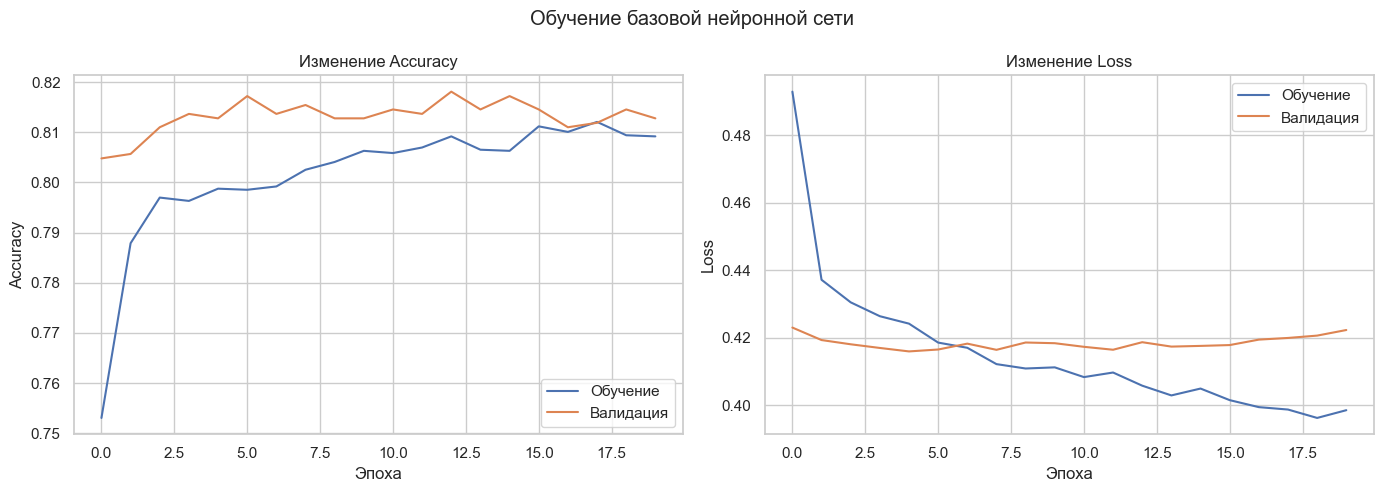

In [60]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    history_baseline.history["accuracy"],
    label="Обучение"
)

axes[0].plot(
    history_baseline.history["val_accuracy"],
    label="Валидация"
)

axes[0].set_title("Изменение Accuracy")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    history_baseline.history["loss"],
    label="Обучение"
)

axes[1].plot(
    history_baseline.history["val_loss"],
    label="Валидация"
)

axes[1].set_title("Изменение Loss")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.suptitle("Обучение базовой нейронной сети")
plt.tight_layout()
plt.savefig("results/neural_network_baseline.png", dpi=300)
plt.show()


На графиках представлено изменение точности классификации (Accuracy) и функции потерь (Loss) на обучающей и валидационной выборках в течение 20 эпох.

В процессе обучения Accuracy увеличилась с 0,7531 до 0,8092, а Loss снизилась с 0,4929 до 0,3985, что свидетельствует об успешном обучении нейронной сети.

На валидационной выборке Accuracy колеблется приблизительно в пределах 0,805–0,818, оставаясь сопоставимой с обучающей точностью. При этом валидационная ошибка после первоначального снижения стабилизируется около 0,42 и к концу обучения немного возрастает.

Таким образом, модель демонстрирует хорошую способность к обобщению, однако расхождение между обучающей и валидационной ошибками указывает на начальные признаки переобучения.

#### 6.4. Исследование влияния гиперпараметров нейронной сети
Для исследования влияния гиперпараметров проводится серия экспериментов с различными конфигурациями нейронной сети.

Варьируются число эпох обучения, размер батча, количество скрытых слоёв, количество нейронов и функция активации.

Для корректного сравнения используется одна и та же обучающая и валидационная выборка. В качестве основной метрики выбора конфигурации применяется F1-score на валидационных данных.

In [61]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

experiments = [
    {
        "name": "Базовая",
        "layers": (64, 32),
        "activation": "relu",
        "epochs": 20,
        "batch_size": 32
    },
    {
        "name": "10 эпох",
        "layers": (64, 32),
        "activation": "relu",
        "epochs": 10,
        "batch_size": 32
    },
    {
        "name": "35 эпох",
        "layers": (64, 32),
        "activation": "relu",
        "epochs": 35,
        "batch_size": 32
    },
    {
        "name": "Batch 16",
        "layers": (64, 32),
        "activation": "relu",
        "epochs": 20,
        "batch_size": 16
    },
    {
        "name": "Batch 64",
        "layers": (64, 32),
        "activation": "relu",
        "epochs": 20,
        "batch_size": 64
    },
    {
        "name": "1 слой",
        "layers": (64,),
        "activation": "relu",
        "epochs": 20,
        "batch_size": 32
    },
    {
        "name": "3 слоя",
        "layers": (128, 64, 32),
        "activation": "relu",
        "epochs": 20,
        "batch_size": 32
    },
    {
        "name": "Меньше нейронов",
        "layers": (32, 16),
        "activation": "relu",
        "epochs": 20,
        "batch_size": 32
    },
    {
        "name": "Больше нейронов",
        "layers": (128, 64),
        "activation": "relu",
        "epochs": 20,
        "batch_size": 32
    },
    {
        "name": "Tanh",
        "layers": (64, 32),
        "activation": "tanh",
        "epochs": 20,
        "batch_size": 32
    }
]

experiment_results = []
experiment_histories = {}

for i, config in enumerate(experiments):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = create_neural_network(
        input_dim=input_dim,
        layers=config["layers"],
        activation=config["activation"]
    )

    callback = tf.keras.callbacks.TensorBoard(
        log_dir=f"logs/tensorboard/experiment_{i:02d}",
        histogram_freq=0
    )

    history = model.fit(
        X_nn_train_processed,
        y_nn_train_array,
        validation_data=(
            X_nn_val_processed,
            y_nn_val_array
        ),
        epochs=config["epochs"],
        batch_size=config["batch_size"],
        callbacks=[callback],
        verbose=0
    )

    y_prob = model.predict(
        X_nn_val_processed,
        verbose=0
    ).ravel()

    y_pred = (y_prob >= 0.5).astype(int)

    result = {
        "Эксперимент": config["name"],
        "Слои": str(config["layers"]),
        "Активация": config["activation"],
        "Эпохи": config["epochs"],
        "Batch": config["batch_size"],
        "Accuracy": accuracy_score(y_nn_val, y_pred),
        "Precision": precision_score(
            y_nn_val, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_nn_val, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_nn_val, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_nn_val, y_prob),
        "Val Loss": history.history["val_loss"][-1]
    }

    experiment_results.append(result)
    experiment_histories[config["name"]] = history.history

    print(
        f"{config['name']}: "
        f"F1 = {result['F1-score']:.4f}, "
        f"AUC = {result['ROC-AUC']:.4f}"
    )

nn_experiments_df = pd.DataFrame(experiment_results)

display(
    nn_experiments_df.sort_values(
        "F1-score",
        ascending=False
    ).round(4)
)

nn_experiments_df.to_csv(
    "results/neural_network_experiments.csv",
    index=False
)


Базовая: F1 = 0.6100, AUC = 0.8420
10 эпох: F1 = 0.6085, AUC = 0.8439
35 эпох: F1 = 0.6058, AUC = 0.8369
Batch 16: F1 = 0.5781, AUC = 0.8427
Batch 64: F1 = 0.6090, AUC = 0.8458
1 слой: F1 = 0.6241, AUC = 0.8490
3 слоя: F1 = 0.6097, AUC = 0.8422
Меньше нейронов: F1 = 0.6111, AUC = 0.8468
Больше нейронов: F1 = 0.6019, AUC = 0.8416
Tanh: F1 = 0.6082, AUC = 0.8488


,Эксперимент,Слои,Активация,Эпохи,Batch,Accuracy,Precision,Recall,F1-score,ROC-AUC,Val Loss
5,1 слой,"(64,)",relu,20,32,0.8172,0.6867,0.5719,0.6241,0.8490,0.4130
7,Меньше нейронов,"(32, 16)",relu,20,32,0.8137,0.6846,0.5518,0.6111,0.8468,0.4177
0,Базовая,"(64, 32)",relu,20,32,0.8128,0.6818,0.5518,0.6100,0.8420,0.4223
6,3 слоя,"(128, 64, 32)",relu,20,32,0.8137,0.6862,0.5485,0.6097,0.8422,0.4243
4,Batch 64,"(64, 32)",relu,20,64,0.8154,0.6953,0.5418,0.6090,0.8458,0.4177
1,10 эпох,"(64, 32)",relu,10,32,0.8128,0.6833,0.5485,0.6085,0.8439,0.4184
9,Tanh,"(64, 32)",tanh,20,32,0.8137,0.6878,0.5452,0.6082,0.8488,0.4118
2,35 эпох,"(64, 32)",relu,35,32,0.8083,0.6667,0.5552,0.6058,0.8369,0.4318
8,Больше нейронов,"(128, 64)",relu,20,32,0.8110,0.6822,0.5385,0.6019,0.8416,0.4272
3,Batch 16,"(64, 32)",relu,20,16,0.8083,0.6948,0.4950,0.5781,0.8427,0.4227


В ходе исследования проведено 10 экспериментов с различными архитектурами и гиперпараметрами нейронной сети. Оценка качества выполнялась на валидационной выборке с использованием метрик Accuracy, Precision, Recall, F1-score и ROC-AUC.

Наибольшее значение F1-score = 0,6241 получено для архитектуры с одним скрытым слоем из 64 нейронов, функцией активации ReLU, 20 эпохами обучения и размером батча 32. Для данной конфигурации Accuracy составила 0,8172, Precision - 0,6867, Recall - 0,5719, а ROC-AUC - 0,8490.

По сравнению с базовой архитектурой F1-score увеличился с 0,6100 до 0,6241, а ROC-AUC - с 0,8420 до 0,8490. Увеличение количества скрытых слоёв до трёх не привело к улучшению качества классификации.

Изменение количества эпох, размера батча и функции активации также не обеспечило более высокого F1-score. При этом уменьшение размера батча до 16 снизило показатель до 0,5781.

Лучшей среди исследованных конфигураций стала нейронная сеть с одним скрытым слоем из 64 нейронов.

Для наглядного сравнения построим столбчатую диаграмму F1-score.

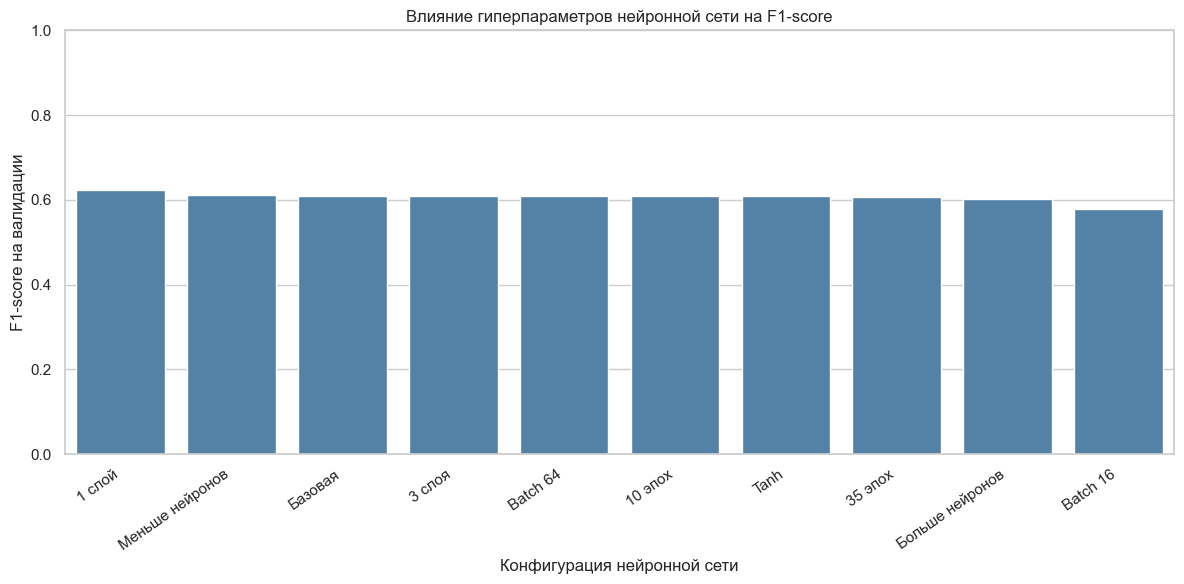

In [62]:

nn_plot_df = nn_experiments_df.sort_values(
    "F1-score",
    ascending=False
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=nn_plot_df,
    x="Эксперимент",
    y="F1-score",
    color="steelblue"
)

plt.title("Влияние гиперпараметров нейронной сети на F1-score")
plt.xlabel("Конфигурация нейронной сети")
plt.ylabel("F1-score на валидации")
plt.xticks(rotation=35, ha="right")
plt.ylim(0, 1)

plt.tight_layout()
plt.savefig("results/neural_network_tuning.png", dpi=300)
plt.show()


На диаграмме представлено сравнение F1-score для десяти конфигураций нейронной сети с различными гиперпараметрами.

Наибольшее значение F1-score = 0,6241 получено для архитектуры с одним скрытым слоем из 64 нейронов. Базовая модель с двумя скрытыми слоями показала результат 0,6100.

Большинство конфигураций продемонстрировали близкие значения F1-score в диапазоне 0,6019-0,6111. Наименьший результат получен при размере батча 16 - 0,5781.

Упрощение архитектуры до одного скрытого слоя позволило повысить качество классификации, тогда как увеличение количества слоёв, нейронов или эпох не обеспечило дополнительного улучшения.

#### 6.5. Анализ лучшей архитектуры нейронной сети
На основании результатов проведённых экспериментов выбирается конфигурация нейронной сети, обеспечившая максимальное значение F1-score на валидационной выборке.

Для выбранной модели анализируются количество скрытых слоёв, число нейронов, функция активации, количество эпох и размер батча.

Дополнительно исследуются графики изменения функции потерь и точности классификации, позволяющие оценить устойчивость обучения и возможные признаки переобучения.

In [64]:

best_index = nn_experiments_df["F1-score"].idxmax()

best_result = nn_experiments_df.loc[best_index]

best_config = next(
    config for config in experiments
    if config["name"] == best_result["Эксперимент"]
)

print("Лучшая конфигурация:")
print("Название:", best_config["name"])
print("Скрытые слои:", best_config["layers"])
print("Активация:", best_config["activation"])
print("Эпохи:", best_config["epochs"])
print("Размер батча:", best_config["batch_size"])

print("\nМетрики на валидационной выборке:")

display(
    nn_experiments_df.loc[
        [best_index],
        ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
    ].round(4)
)


Лучшая конфигурация:
Название: 1 слой
Скрытые слои: (64,)
Активация: relu
Эпохи: 20
Размер батча: 32

Метрики на валидационной выборке:


,Accuracy,Precision,Recall,F1-score,ROC-AUC
5,0.8172,0.6867,0.5719,0.6241,0.849


По результатам исследования гиперпараметров выбрана оптимальная архитектура нейронной сети, содержащая один скрытый слой из 64 нейронов с функцией активации ReLU. Количество эпох обучения составило 20, размер батча - 32.

На валидационной выборке модель достигла следующих показателей: Accuracy = 0,8172, Precision = 0,6867, Recall = 0,5719, F1-score = 0,6241 и ROC-AUC = 0,8490.

Высокое значение ROC-AUC свидетельствует о хорошей способности модели различать клиентов, склонных к оттоку, и клиентов, продолжающих пользоваться услугами. При этом Recall = 0,5719 показывает, что модель обнаруживает около 57% клиентов с фактическим оттоком при пороге классификации 0,5.

Графики обучения лучшей модели:


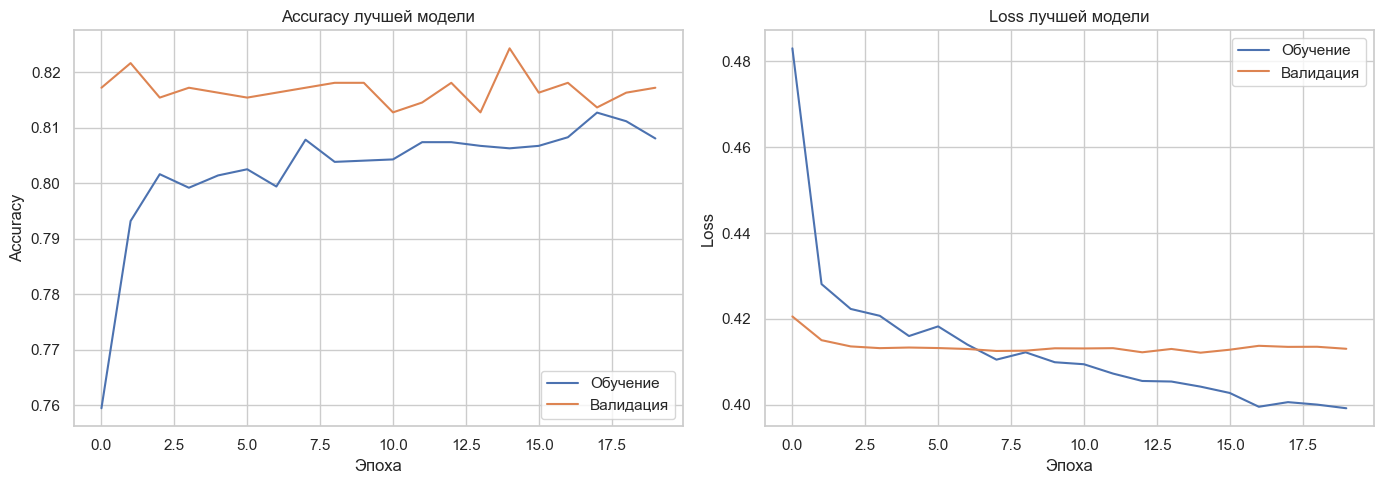

In [65]:

best_history = experiment_histories[best_config["name"]]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    best_history["accuracy"],
    label="Обучение"
)

axes[0].plot(
    best_history["val_accuracy"],
    label="Валидация"
)

axes[0].set_title("Accuracy лучшей модели")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    best_history["loss"],
    label="Обучение"
)

axes[1].plot(
    best_history["val_loss"],
    label="Валидация"
)

axes[1].set_title("Loss лучшей модели")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("results/best_neural_network_history.png", dpi=300)
plt.show()


На графиках представлено изменение точности классификации (Accuracy) и функции потерь (Loss) на обучающей и валидационной выборках в течение 20 эпох.

В процессе обучения Accuracy увеличилась приблизительно с 0,76 до 0,81, а Loss снизилась с 0,483 до 0,399, что свидетельствует об успешной оптимизации параметров нейронной сети.

#### 6.6. Мониторинг процесса обучения с помощью TensorBoard
Для визуального анализа процесса обучения нейронной сети используется инструмент TensorBoard.

В ходе экспериментов сохраняются значения функции потерь и точности классификации на обучающей и валидационной выборках.

TensorBoard позволяет исследовать динамику loss, accuracy, val_loss и val_accuracy, сравнивать различные конфигурации нейронной сети и выявлять возможные признаки переобучения.

In [68]:

%load_ext tensorboard
%tensorboard --logdir logs/tensorboard


The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


Reusing TensorBoard on port 6006 (pid 12756), started 0:02:57 ago. (Use '!kill 12756' to kill it.)

На графиках TensorBoard представлена динамика точности классификации (Accuracy) и функции потерь (Loss) для базовой нейронной сети и десяти экспериментальных конфигураций.

В процессе обучения наблюдается увеличение Accuracy и снижение Loss, что свидетельствует об успешной оптимизации параметров нейронных сетей. Для базовой модели итоговая точность составила 0,8092 на обучающей выборке и 0,8128 на валидационной.

Валидационная ошибка базовой модели составила 0,4223, тогда как обучающая снизилась до 0,3985. Для отдельных конфигураций наблюдается увеличение валидационной ошибки при дальнейшем снижении обучающей, что указывает на возможное переобучение.

Сравнение экспериментальных кривых показывает, что различные гиперпараметры влияют на скорость сходимости и устойчивость обучения.

#### 6.7. Итоговое обучение и оценка нейронной сети

После определения наиболее эффективной конфигурации выполняется итоговое обучение нейронной сети на всей обучающей выборке.

Для подготовки данных используются ранее созданные методы заполнения пропусков, кодирования категориальных признаков и стандартизации числовых переменных.

Количество эпох, размер батча, архитектура и функция активации устанавливаются на основании результатов экспериментов с валидационной выборкой.

Качество итоговой модели оценивается по метрикам Accuracy, Precision, Recall, F1-score и ROC-AUC на независимой тестовой выборке. Дополнительно строится матрица ошибок.

In [69]:

final_preprocessor = clone(preprocessor)

X_train_final = final_preprocessor.fit_transform(
    X_train_nn
).astype("float32")

X_test_final = final_preprocessor.transform(
    X_test_nn
).astype("float32")

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

final_nn = create_neural_network(
    input_dim=X_train_final.shape[1],
    layers=best_config["layers"],
    activation=best_config["activation"]
)

final_history = final_nn.fit(
    X_train_final,
    y_train.to_numpy().astype("float32"),
    epochs=best_config["epochs"],
    batch_size=best_config["batch_size"],
    callbacks=[
        tf.keras.callbacks.TensorBoard(
            log_dir="logs/tensorboard/final_model"
        )
    ],
    verbose=0
)

y_prob_nn = final_nn.predict(
    X_test_final,
    verbose=0
).ravel()

y_pred_nn = (y_prob_nn >= 0.5).astype(int)

nn_metrics = {
    "Модель": "TensorFlow NN",
    "Accuracy": accuracy_score(y_test, y_pred_nn),
    "Precision": precision_score(y_test, y_pred_nn, zero_division=0),
    "Recall": recall_score(y_test, y_pred_nn, zero_division=0),
    "F1-score": f1_score(y_test, y_pred_nn, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob_nn)
}

display(pd.DataFrame([nn_metrics]).round(4))

pd.DataFrame([nn_metrics]).to_csv(
    "results/neural_network_metrics.csv",
    index=False
)

final_nn.save("results/telco_neural_network.keras")


,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,TensorFlow NN,0.7984,0.6596,0.4973,0.5671,0.843


После настройки гиперпараметров и итогового обучения нейронной сети проведена оценка качества классификации на независимой тестовой выборке.

Получены следующие показатели: Accuracy = 0,7984, Precision = 0,6596, Recall = 0,4973, F1-score = 0,5671 и ROC-AUC = 0,8430.

Значение Accuracy показывает, что модель правильно классифицирует около 79,84% клиентов. При этом Precision = 0,6596 означает, что примерно 66% клиентов, отнесённых моделью к группе оттока, действительно прекратили обслуживание.

Показатель Recall = 0,4973 свидетельствует о том, что нейронная сеть обнаруживает около 49,73% клиентов с фактическим оттоком при пороге классификации 0,5.

По сравнению с лучшим результатом на валидационной выборке F1-score снизился с 0,6241 до 0,5671. При этом ROC-AUC сохранился на относительно высоком уровне - 0,8430.

Матрица ошибок и ROC-кривая нейронной сети:

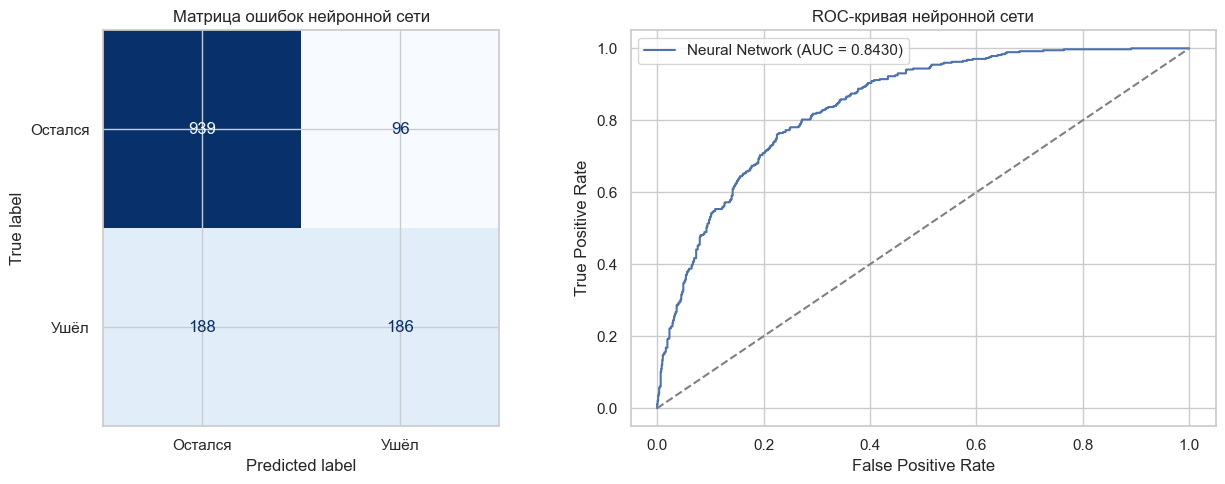

Метрики нейронной сети:
Accuracy: 0.7984
Precision: 0.6596
Recall: 0.4973
F1-score: 0.5671
ROC-AUC: 0.8430

Матрица ошибок:
TN: 939
FP: 96
FN: 188
TP: 186


In [70]:

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve
)

cm_nn = confusion_matrix(y_test, y_pred_nn)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_nn,
    display_labels=["Остался", "Ушёл"]
)

disp.plot(
    ax=axes[0],
    cmap="Blues",
    colorbar=False
)

axes[0].set_title("Матрица ошибок нейронной сети")

fpr_nn, tpr_nn, _ = roc_curve(y_test, y_prob_nn)

axes[1].plot(
    fpr_nn,
    tpr_nn,
    label=f"Neural Network (AUC = {nn_metrics['ROC-AUC']:.4f})"
)

axes[1].plot(
    [0, 1],
    [0, 1],
    "--",
    color="gray"
)

axes[1].set_title("ROC-кривая нейронной сети")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("results/neural_network_evaluation.png", dpi=300)
plt.show()

tn, fp, fn, tp = cm_nn.ravel()

print("Метрики нейронной сети:")

for metric, value in nn_metrics.items():
    if metric != "Модель":
        print(f"{metric}: {value:.4f}")

print("\nМатрица ошибок:")
print(f"TN: {tn}")
print(f"FP: {fp}")
print(f"FN: {fn}")
print(f"TP: {tp}")


Матрица ошибок показывает, что нейронная сеть правильно классифицировала 939 клиентов, оставшихся в компании (TN), и 186 клиентов, прекративших обслуживание (TP). При этом 96 клиентов ошибочно отнесены к группе оттока (FP), а 188 клиентов с фактическим оттоком не были обнаружены моделью (FN).

Полученные результаты соответствуют значениям Accuracy = 0,7984, Precision = 0,6596, Recall = 0,4973 и F1-score = 0,5671.

ROC-кривая располагается значительно выше диагональной линии случайного классификатора. Значение ROC-AUC = 0,8430 свидетельствует о хорошей способности нейронной сети различать клиентов двух классов.

Нейронная сеть эффективно распознаёт клиентов, продолжающих пользоваться услугами, но обнаруживает только около половины случаев оттока при пороге классификации 0,5.

#### 6.8. Выводы по результатам исследования нейронной сети
Наилучшие результаты на валидационной выборке продемонстрировала архитектура с одним скрытым слоем из 64 нейронов, функцией активации ReLU, 20 эпохами обучения и размером батча 32. Для данной конфигурации получены значения Accuracy = 0,8172, F1-score = 0,6241 и ROC-AUC = 0,8490.

Анализ графиков обучения показал увеличение точности классификации и снижение функции потерь. При этом к концу обучения наблюдались незначительные признаки переобучения, выраженные в расхождении обучающей и валидационной ошибок. Использование TensorBoard позволило отслеживать процесс обучения и сравнивать поведение различных архитектур.

После выбора оптимальных гиперпараметров нейронная сеть была повторно обучена на всей обучающей выборке и оценена на независимых тестовых данных. Получены следующие показатели:

Accuracy = 0,7984 - правильно классифицировано 79,84% клиентов.

Precision = 0,6596 - 65,96% клиентов, отнесённых к группе оттока, действительно прекратили обслуживание.

Recall = 0,4973 - обнаружено 49,73% клиентов с фактическим оттоком.

F1-score = 0,5671 - характеризует баланс между точностью положительных прогнозов и полнотой обнаружения оттока.

ROC-AUC = 0,8430 - свидетельствует о хорошей способности модели различать два класса.

Анализ матрицы ошибок показал, что нейронная сеть правильно определила 939 клиентов без оттока и 186 клиентов с оттоком. При этом было допущено 96 ложноположительных и 188 ложноотрицательных ошибок.

Сравнение результатов на валидационной и тестовой выборках показало снижение F1-score с 0,6241 до 0,5671. Это свидетельствует о том, что качество классификации зависит от используемой выборки и выбранная архитектура не обеспечивает одинаково высоких результатов на всех данных.

Вместе с тем значение ROC-AUC = 0,8430 показывает, что модель сохраняет хорошую способность разделять классы. Относительно невысокий Recall указывает на возможность дальнейшего улучшения обнаружения оттока, например за счёт изменения порога классификации и учёта дисбаланса классов.

### 7. Сравнительный анализ методов классификации
Для сравнительного анализа используются результаты восьми классических методов классификации после настройки гиперпараметров и итоговой нейронной сети TensorFlow.

Все модели оцениваются на одной тестовой выборке, содержащей 1409 наблюдений. Для сравнения применяются метрики Accuracy, Precision, Recall, F1-score и ROC-AUC.

Основным критерием выбора модели является F1-score, характеризующий баланс между Precision и Recall. Дополнительно рассматриваются полнота обнаружения клиентов с оттоком и способность алгоритмов различать два класса.

In [71]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

Path("results").mkdir(exist_ok=True)

classical_metrics = [
    ["GaussianNB", 0.6955, 0.4597, 0.8396, 0.5941, 0.8075],
    ["MultinomialNB", 0.7090, 0.4716, 0.7995, 0.5933, 0.8066],
    ["ComplementNB", 0.6785, 0.4444, 0.8449, 0.5825, 0.8066],
    ["BernoulliNB", 0.7182, 0.4815, 0.7995, 0.6010, 0.8069],
    ["Decision Tree", 0.7984, 0.6347, 0.5668, 0.5989, 0.8282],
    ["LDA", 0.7686, 0.5498, 0.7086, 0.6192, 0.8346],
    ["SVM", 0.7864, 0.6130, 0.5294, 0.5681, 0.8237],
    ["kNN", 0.7771, 0.5824, 0.5668, 0.5745, 0.8249]
]

metric_columns = [
    "Модель",
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC"
]

classical_df = pd.DataFrame(
    classical_metrics,
    columns=metric_columns
)

neural_df = pd.DataFrame([nn_metrics])[metric_columns]

comparison_df = pd.concat(
    [classical_df, neural_df],
    ignore_index=True
)

comparison_df = comparison_df.sort_values(
    "F1-score",
    ascending=False
).reset_index(drop=True)

display(comparison_df.round(4))

comparison_df.to_csv(
    "results/final_models_comparison.csv",
    index=False
)


,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,LDA,0.7686,0.5498,0.7086,0.6192,0.8346
1,BernoulliNB,0.7182,0.4815,0.7995,0.6010,0.8069
2,Decision Tree,0.7984,0.6347,0.5668,0.5989,0.8282
3,GaussianNB,0.6955,0.4597,0.8396,0.5941,0.8075
4,MultinomialNB,0.7090,0.4716,0.7995,0.5933,0.8066
5,ComplementNB,0.6785,0.4444,0.8449,0.5825,0.8066
6,kNN,0.7771,0.5824,0.5668,0.5745,0.8249
7,SVM,0.7864,0.6130,0.5294,0.5681,0.8237
8,TensorFlow NN,0.7984,0.6596,0.4973,0.5671,0.8430


Сравнение девяти классификаторов показало, что наибольшее значение F1-score = 0,6192 достигнуто методом линейного дискриминантного анализа (LDA). При этом его Recall составил 0,7086, а ROC-AUC - 0,8346.

Наибольшее значение ROC-AUC = 0,8430 продемонстрировала нейронная сеть TensorFlow. Однако её F1-score составил 0,5671, а Recall - 0,4973.

Максимальная Accuracy = 0,7984 получена у дерева решений и нейронной сети. Наибольший Recall = 0,8449 достигнут методом ComplementNB.

Различные алгоритмы имеют преимущества по разным метрикам. LDA обеспечивает наиболее высокий F1-score, нейронная сеть лучше остальных разделяет классы по ROC-AUC, а ComplementNB наиболее полно обнаруживает клиентов с оттоком при пороге классификации 0,5.

Для визуального сравнения эффективности классификаторов строятся столбчатые диаграммы основных метрик.

Особое внимание уделяется F1-score, поскольку набор данных характеризуется неравномерным распределением классов. Высокая общая точность классификации не всегда означает эффективное обнаружение клиентов, склонных к оттоку.

Сравнение F1-score позволяет определить модель, обеспечивающую наиболее сбалансированное сочетание Precision и Recall.

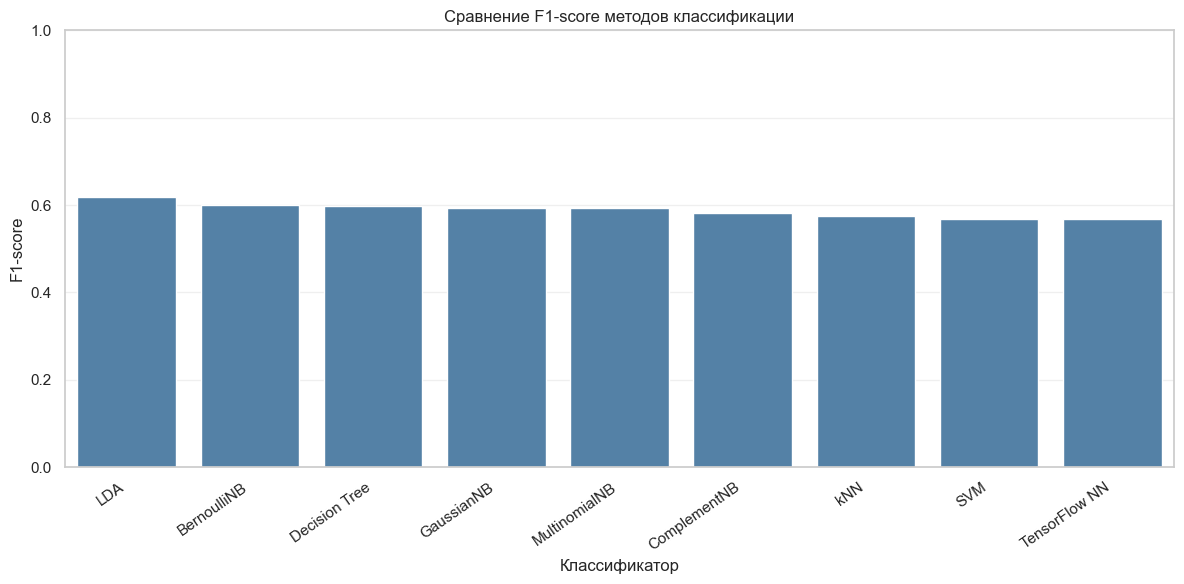

In [72]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison_df,
    x="Модель",
    y="F1-score",
    color="steelblue"
)

plt.title("Сравнение F1-score методов классификации")
plt.xlabel("Классификатор")
plt.ylabel("F1-score")
plt.xticks(rotation=35, ha="right")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("results/comparison_f1.png", dpi=300)
plt.show()


Наибольшее значение F1-score продемонстрировал классификатор LDA - 0,6192. Второе место занимает BernoulliNB с результатом 0,6010, третье - дерево решений с F1-score = 0,5989.

Нейронная сеть TensorFlow достигла значения F1-score = 0,5671, уступив большинству классических алгоритмов.

Разница между LDA и нейронной сетью составила 0,0521.

По критерию баланса между Precision и Recall наиболее эффективным алгоритмом оказался LDA. Использование более сложной нейросетевой архитектуры не привело к повышению F1-score на тестовой выборке.

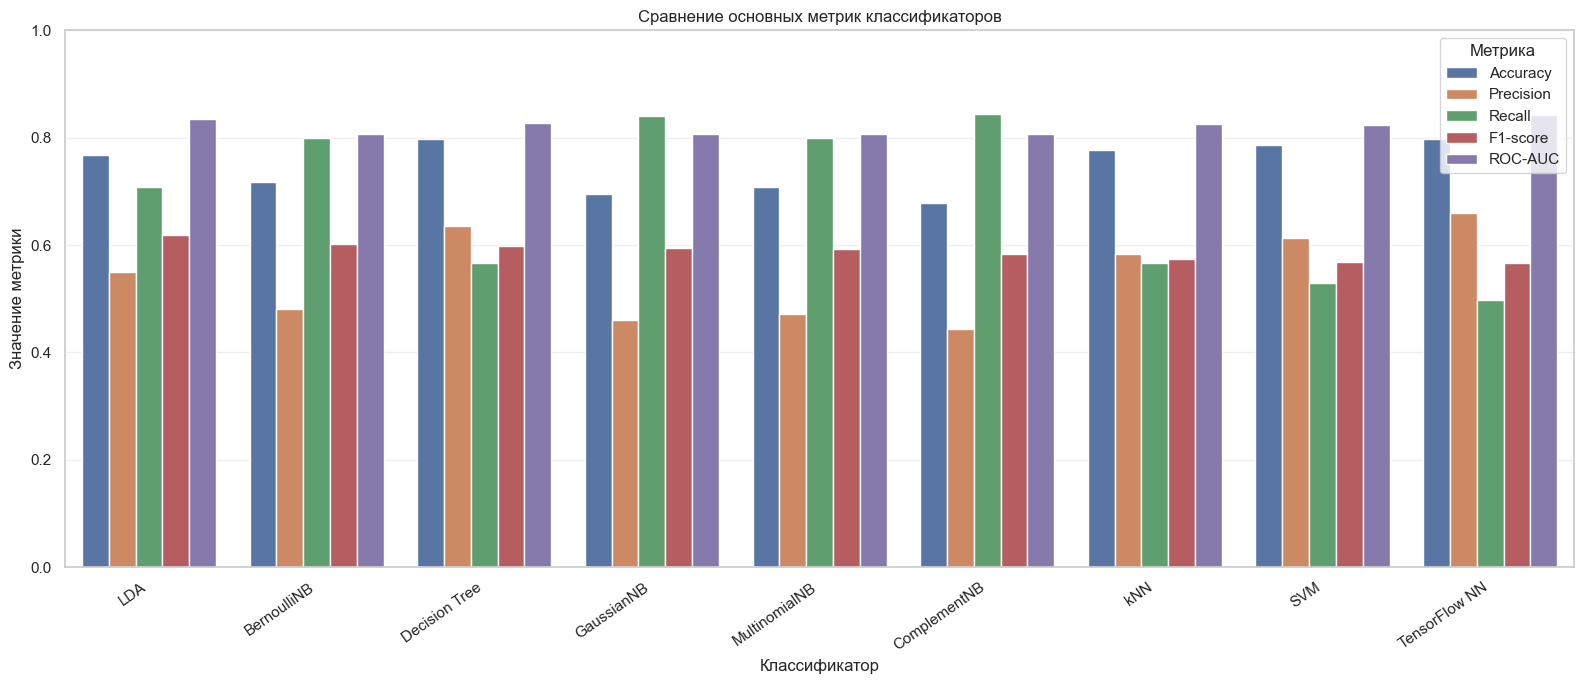

In [73]:

metrics_long = comparison_df.melt(
    id_vars="Модель",
    value_vars=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    var_name="Метрика",
    value_name="Значение"
)

plt.figure(figsize=(16, 7))

sns.barplot(
    data=metrics_long,
    x="Модель",
    y="Значение",
    hue="Метрика"
)

plt.title("Сравнение основных метрик классификаторов")
plt.xlabel("Классификатор")
plt.ylabel("Значение метрики")
plt.xticks(rotation=35, ha="right")
plt.ylim(0, 1)
plt.legend(title="Метрика", loc="upper right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("results/comparison_all_metrics.png", dpi=300)
plt.show()


Диаграмма демонстрирует различия в качестве классификации между рассмотренными алгоритмами.

Наибольшая Accuracy = 0,7984 наблюдается у дерева решений и нейронной сети TensorFlow. Нейронная сеть также достигает максимального Precision = 0,6596 и ROC-AUC = 0,8430.

Байесовские классификаторы отличаются высокой полнотой обнаружения оттока. Максимальный Recall = 0,8449 получен у ComplementNB, однако его Precision составляет 0,4444, что указывает на значительное количество ложноположительных прогнозов.

LDA обеспечивает наиболее сбалансированные результаты с F1-score = 0,6192 и Recall = 0,7086.

Выбор классификатора зависит от приоритетной метрики. Для сбалансированного прогнозирования оттока предпочтителен LDA, а при необходимости обнаружить максимальное количество потенциально уходящих клиентов можно рассмотреть ComplementNB.

Для дополнительной оценки качества классификации проводится сравнение ROC-кривых всех исследованных алгоритмов.

ROC-кривая отражает зависимость доли правильно обнаруженных положительных объектов (True Positive Rate) от доли ложноположительных прогнозов (False Positive Rate) при изменении порога классификации.

В качестве интегрального показателя используется площадь под ROC-кривой - ROC-AUC. Чем ближе значение ROC-AUC к 1, тем выше способность модели различать клиентов с оттоком и без оттока.

In [74]:

from sklearn.base import clone
from sklearn.naive_bayes import (
    GaussianNB,
    MultinomialNB,
    ComplementNB,
    BernoulliNB
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import roc_curve, roc_auc_score

preprocessor_standard_roc = clone(preprocessor)
preprocessor_positive_roc = clone(preprocessor_nonnegative)

X_train_standard = preprocessor_standard_roc.fit_transform(
    X_train_nn
)

X_test_standard = preprocessor_standard_roc.transform(
    X_test_nn
)

X_train_positive = preprocessor_positive_roc.fit_transform(
    X_train_nn
)

X_test_positive = preprocessor_positive_roc.transform(
    X_test_nn
)

def to_dense_float32(array):
    if hasattr(array, "toarray"):
        array = array.toarray()

    return np.asarray(array, dtype=np.float32)

X_train_standard = to_dense_float32(X_train_standard)
X_test_standard = to_dense_float32(X_test_standard)
X_train_positive = to_dense_float32(X_train_positive)
X_test_positive = to_dense_float32(X_test_positive)

roc_models = {
    "GaussianNB": GaussianNB(var_smoothing=1e-11),
    "MultinomialNB": MultinomialNB(alpha=0.01),
    "ComplementNB": ComplementNB(alpha=0.01),
    "BernoulliNB": BernoulliNB(alpha=1.0),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=10,
        min_samples_split=2,
        random_state=42
    ),
    "LDA": LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage=0.7
    ),
    "SVM": SVC(
        C=10,
        kernel="linear"
    ),
    "kNN": KNeighborsClassifier(
        n_neighbors=21,
        metric="manhattan",
        weights="uniform"
    )
}

positive_models = [
    "MultinomialNB",
    "ComplementNB",
    "BernoulliNB"
]

roc_probabilities = {}

for name, model in roc_models.items():
    if name in positive_models:
        X_fit = X_train_positive
        X_eval = X_test_positive
    else:
        X_fit = X_train_standard
        X_eval = X_test_standard

    model.fit(X_fit, y_train)

    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X_eval)[:, 1]
    else:
        scores = model.decision_function(X_eval)

    roc_probabilities[name] = scores

roc_probabilities["TensorFlow NN"] = y_prob_nn

print("Подготовлено моделей:", len(roc_probabilities))

for name, scores in roc_probabilities.items():
    auc = roc_auc_score(y_test, scores)
    print(f"{name}: ROC-AUC = {auc:.4f}")


Подготовлено моделей: 9
GaussianNB: ROC-AUC = 0.8075
MultinomialNB: ROC-AUC = 0.8066
ComplementNB: ROC-AUC = 0.8066
BernoulliNB: ROC-AUC = 0.8006
Decision Tree: ROC-AUC = 0.8282
LDA: ROC-AUC = 0.8346
SVM: ROC-AUC = 0.8236
kNN: ROC-AUC = 0.8249
TensorFlow NN: ROC-AUC = 0.8430


Наибольшее значение ROC-AUC = 0,8430 продемонстрировала нейронная сеть TensorFlow. Второе место занял классификатор LDA с результатом 0,8346, третье - дерево решений с ROC-AUC = 0,8282.

Методы kNN и SVM также показали высокие результаты - 0,8249 и 0,8236 соответственно. Наивные байесовские классификаторы продемонстрировали значения ROC-AUC в диапазоне 0,8006-0,8075.

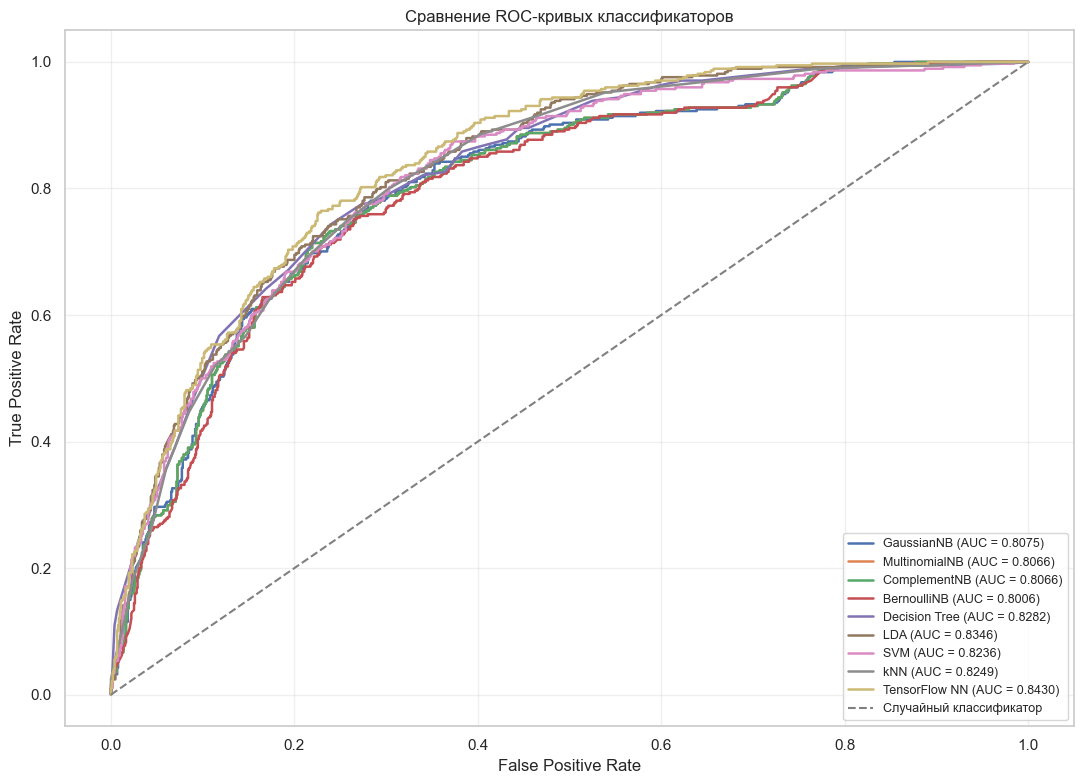

In [75]:

plt.figure(figsize=(11, 8))

for name, scores in roc_probabilities.items():
    fpr, tpr, thresholds = roc_curve(y_test, scores)
    auc = roc_auc_score(y_test, scores)

    plt.plot(
        fpr,
        tpr,
        linewidth=1.8,
        label=f"{name} (AUC = {auc:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Случайный классификатор"
)

plt.title("Сравнение ROC-кривых классификаторов")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right", fontsize=9)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("results/comparison_roc_curves.png", dpi=300)
plt.show()


По результатам итоговой оценки наибольший ROC-AUC продемонстрировала нейронная сеть TensorFlow - 0,8430. Близкое значение получено для классификатора LDA - 0,8346.

Дерево решений, kNN и SVM также показали достаточно высокие значения ROC-AUC: 0,8282, 0,8249 и 0,8237 соответственно.

Байесовские классификаторы продемонстрировали значения ROC-AUC приблизительно от 0,8066 до 0,8075.

Нейронная сеть обеспечивает наилучшее разделение клиентов двух классов по показателю ROC-AUC, однако преимущество над LDA относительно невелико.

Для обоснованного выбора итоговой модели сравниваются максимальные значения пяти метрик классификации.

Поскольку в задаче прогнозирования оттока важно выявлять потенциально уходящих клиентов, особое внимание уделяется F1-score и Recall.

Дополнительно учитывается ROC-AUC, позволяющий оценить способность модели различать классы независимо от конкретного порога классификации.

In [76]:

metrics_to_compare = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC"
]

best_by_metric = []

for metric in metrics_to_compare:
    max_value = comparison_df[metric].max()

    best_names = comparison_df.loc[
        np.isclose(comparison_df[metric], max_value),
        "Модель"
    ].tolist()

    best_by_metric.append({
        "Метрика": metric,
        "Лучшая модель": ", ".join(best_names),
        "Значение": max_value
    })

best_by_metric_df = pd.DataFrame(best_by_metric)

display(best_by_metric_df.round(4))

best_by_metric_df.to_csv(
    "results/best_models_by_metric.csv",
    index=False
)


,Метрика,Лучшая модель,Значение
0,Accuracy,TensorFlow NN,0.7984
1,Precision,TensorFlow NN,0.6596
2,Recall,ComplementNB,0.8449
3,F1-score,LDA,0.6192
4,ROC-AUC,TensorFlow NN,0.8430


По результатам сравнения максимальная Accuracy = 0,7984 достигнута деревом решений и нейронной сетью TensorFlow.

Нейронная сеть также показала наибольшие значения Precision = 0,6596 и ROC-AUC = 0,8430. Это свидетельствует о сравнительно высокой точности положительных прогнозов и хорошей способности разделять классы.

Наибольший Recall = 0,8449 продемонстрировал ComplementNB, обнаруживающий около 84,49% клиентов с фактическим оттоком. Однако его Precision = 0,4444 указывает на большое количество ложных предупреждений.

Наибольший F1-score = 0,6192 достигнут классификатором LDA.

Для задачи прогнозирования оттока наиболее сбалансированным вариантом среди исследованных моделей является LDA. При приоритете максимальной полноты обнаружения оттока предпочтение может быть отдано ComplementNB, а при необходимости более высокого Precision - нейронной сети TensorFlow.

**Выводы:**

Для оценки эффективности использовались метрики Accuracy, Precision, Recall, F1-score и ROC-AUC. Сравнение проводилось на единой тестовой выборке, содержащей 1409 наблюдений.

Наибольшее значение F1-score = 0,6192 продемонстрировал метод линейного дискриминантного анализа (LDA). Его Recall составил 0,7086, а ROC-AUC - 0,8346. Данные результаты свидетельствуют о хорошем балансе между точностью положительных прогнозов и полнотой обнаружения клиентов с оттоком.

Нейронная сеть TensorFlow достигла максимальных значений ROC-AUC = 0,8430 и Precision = 0,6596, однако её F1-score составил 0,5671. Это показывает, что высокая способность модели различать классы не обязательно обеспечивает наилучший результат при фиксированном пороге классификации.

Метод ComplementNB продемонстрировал наибольшую полноту обнаружения оттока - Recall = 0,8449. Вместе с тем его Precision = 0,4444 указывает на повышенное количество ложноположительных прогнозов.

Максимальная Accuracy = 0,7984 достигнута деревом решений и нейронной сетью TensorFlow. Однако в условиях неравномерного распределения классов данная метрика не может рассматриваться как единственный критерий качества.

Графическое сравнение F1-score и ROC-кривых подтвердило различия в эффективности исследованных алгоритмов. Классические методы продемонстрировали конкурентоспособные результаты относительно нейронной сети, несмотря на меньшую сложность отдельных моделей.

Таким образом, наиболее эффективным классификатором по основному критерию F1-score выбран метод LDA с параметром регуляризации shrinkage = 0,7.

### 8.Заключение
В ходе выполнения лабораторной работы исследованы методы классификации и нейронные сети для решения задачи прогнозирования оттока клиентов телекоммуникационной компании.

В качестве исходных данных использован набор Telco Customer Churn, содержащий 7043 наблюдения и 21 исходный столбец. Целевой переменной выбран признак Churn, характеризующий факт прекращения обслуживания клиента.

На этапе предварительной обработки выполнены анализ структуры данных, обработка пропущенных значений, кодирование категориальных переменных и масштабирование числовых признаков. Идентификатор клиента исключён из обучающих признаков. Данные разделены на обучающую и тестовую выборки в соотношении 80% и 20% с сохранением распределения классов.

В рамках исследования реализованы восемь классических классификаторов: GaussianNB, MultinomialNB, ComplementNB, BernoulliNB, Decision Tree, LDA, SVM и kNN. Для каждой модели рассчитаны метрики Accuracy, Precision, Recall, F1-score и ROC-AUC.

Для повышения качества классификации проведена настройка гиперпараметров с использованием GridSearchCV и трёхблочной стратифицированной кросс-валидации. Наибольшее улучшение F1-score продемонстрировало дерево решений: значение метрики увеличилось с 0,4941 до 0,5989.

Дополнительно разработана полносвязная нейронная сеть с использованием библиотек TensorFlow и Keras. Проведено десять экспериментов, в ходе которых исследовано влияние количества скрытых слоёв, числа нейронов, функций активации, количества эпох обучения и размера батча.

Наилучшей среди исследованных нейросетевых архитектур оказалась модель с одним скрытым слоем из 64 нейронов, функцией активации ReLU, 20 эпохами и размером батча 32. Для мониторинга процесса обучения использовался TensorBoard, позволивший визуализировать изменение функции потерь и точности классификации.

На независимой тестовой выборке нейронная сеть достигла Accuracy = 0,7984, Precision = 0,6596, Recall = 0,4973, F1-score = 0,5671 и ROC-AUC = 0,8430.

По результатам итогового сравнительного анализа установлено, что наибольший F1-score = 0,6192 продемонстрировал метод линейного дискриминантного анализа (LDA) с параметром shrinkage = 0,7. При этом Recall составил 0,7086, а ROC-AUC - 0,8346.

Нейронная сеть TensorFlow показала наибольшую площадь под ROC-кривой (0,8430), а классификатор ComplementNB обеспечил максимальную полноту обнаружения оттока (0,8449). Это подтверждает, что различные алгоритмы имеют преимущества в зависимости от выбранного критерия эффективности.

Исследование показало, что усложнение архитектуры модели не всегда приводит к улучшению качества классификации. Для рассматриваемого набора табличных данных классический метод LDA обеспечил более высокий F1-score по сравнению с разработанной нейронной сетью при пороге классификации 0,5.